In [22]:
from pathlib import Path
import pandas as pd

root = Path("/work/magroup/skrieger/Syndri/data/datasets")
datasets = [
    "agingbrain_merfish",
    "brain_merfish",
    "nsclc_cosmx",
    "breast_xenium",
]

frames = []
for dataset in datasets:
    for path in sorted(
        (root / dataset / "results/metrics/non_tcell").glob(
            "*/non_tcell_metrics.csv"
        )
    ):
        frame = pd.read_csv(path)
        frame["dataset"] = dataset
        frame["slice"] = path.parent.name
        frames.append(frame)

if not frames:
    raise FileNotFoundError("No non-T-cell metric CSVs found.")

metrics = pd.concat(frames, ignore_index=True)

failed = metrics["error"].fillna("").ne("")
# display(metrics.loc[failed, ["dataset", "slice", "case", "error"]])

valid_metrics = metrics.loc[~failed].copy()

metric_columns = [
    "silhouette_score",
    "calinski_harabasz",
    "davies_bouldin",
    "leiden_nmi_vs_label",
    "leiden_adjusted_rand_vs_label",
    "median_genes_per_cell",
    "median_transcripts_per_cell",
]

display(
    valid_metrics[
        ["dataset", "slice", "case", "target_removed_fraction",
         "achieved_removed_fraction", *metric_columns]
    ]
)

,dataset,slice,case,target_removed_fraction,achieved_removed_fraction,silhouette_score,calinski_harabasz,davies_bouldin,leiden_nmi_vs_label,leiden_adjusted_rand_vs_label,median_genes_per_cell,median_transcripts_per_cell
0,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,admixed,NaN,NaN,0.309339,731.352972,2.613294,0.875037,0.801035,56.0,148.000000
1,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.01,0.01,0.01000,0.309230,731.017426,2.613442,0.854102,0.742075,56.0,146.567570
2,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.02,0.02,0.02000,0.309116,730.671658,2.613842,0.850349,0.725763,56.0,145.130932
3,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.05,0.05,0.05000,0.308742,729.566494,2.616502,0.848919,0.716708,56.0,140.837850
4,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.1,0.10,0.10000,0.307906,727.450828,2.631798,0.850624,0.739134,56.0,133.461062
...,...,...,...,...,...,...,...,...,...,...,...,...
457,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.3,0.30,0.30000,0.185841,4904.171532,6.518685,0.540915,0.340257,49.0,72.743849
458,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.4,0.40,0.40000,0.256160,6784.766711,5.830039,0.634070,0.505099,43.0,60.087027
459,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.5,0.50,0.50000,0.302895,7264.102743,5.242906,0.625096,0.351431,33.0,48.306420
460,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,SPLIT,NaN,NaN,0.144495,4522.388296,7.179083,0.448881,0.429027,49.0,74.557637


In [35]:
metrics['threshold_selection'].unique()

array([nan, 'per_cell_rolling_reference_cosine'], dtype=object)

In [3]:
pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/metrics/non_tcell/GSM9509165_breast_breast_B4_B4_rctd_annotated/syndri_thresholds/GSM9509165_breast_breast_B4_B4_rctd_annotated.3318c94c8e86.csv').groupby('cell_type')['n_removed_genes'].mean()

cell_type
CD4-positive, alpha-beta memory T cell    29.293939
capillary endothelial cell                21.064670
classical monocyte                        24.253487
cytotoxic T cell                          30.375991
fibroblast of breast                      18.445484
fibroblast of lung                        17.873863
macrophage                                18.546661
malignant cell                            10.776159
mast cell                                 23.405405
natural T-regulatory cell                 28.966019
natural killer cell                       24.470199
pericyte                                  21.967213
plasma cell                               24.997290
plasmacytoid dendritic cell               15.175287
smooth muscle cell                        20.600371
Name: n_removed_genes, dtype: float64

In [4]:
metrics[(metrics['dataset']=='brain_merfish')
        &(metrics['case'].isin(['cleaned_admixed_removed_frac_0.01','cleaned_admixed_removed_frac_0.5']))][['case','tissue','davies_bouldin']]

,case,tissue,davies_bouldin
133,cleaned_admixed_removed_frac_0.01,st_integrated_slice-Zhuang-ABCA-4.001,1.914945
140,cleaned_admixed_removed_frac_0.5,st_integrated_slice-Zhuang-ABCA-4.001,1.806715
144,cleaned_admixed_removed_frac_0.01,st_integrated_slice-Zhuang-ABCA-4.002,2.122136
151,cleaned_admixed_removed_frac_0.5,st_integrated_slice-Zhuang-ABCA-4.002,1.969323
155,cleaned_admixed_removed_frac_0.01,st_integrated_slice-Zhuang-ABCA-4.003,1.959176
162,cleaned_admixed_removed_frac_0.5,st_integrated_slice-Zhuang-ABCA-4.003,1.657601


In [5]:
metrics[metrics['tissue'].str.startswith('cosmx')]

,tissue,source_file,case,cleaning_mode,cell_type_specific_removal,probability_transform,probability_removal_scale,group_admix_prob_thresholds,group_probability_removal_scales,group_achieved_removed_fractions,...,error,median_genes_per_cell,median_transcripts_per_cell,threshold_selection,cosine_window,reference_profiles,syndri_probability_ordering,syndri_min_removal_probability,dataset,slice


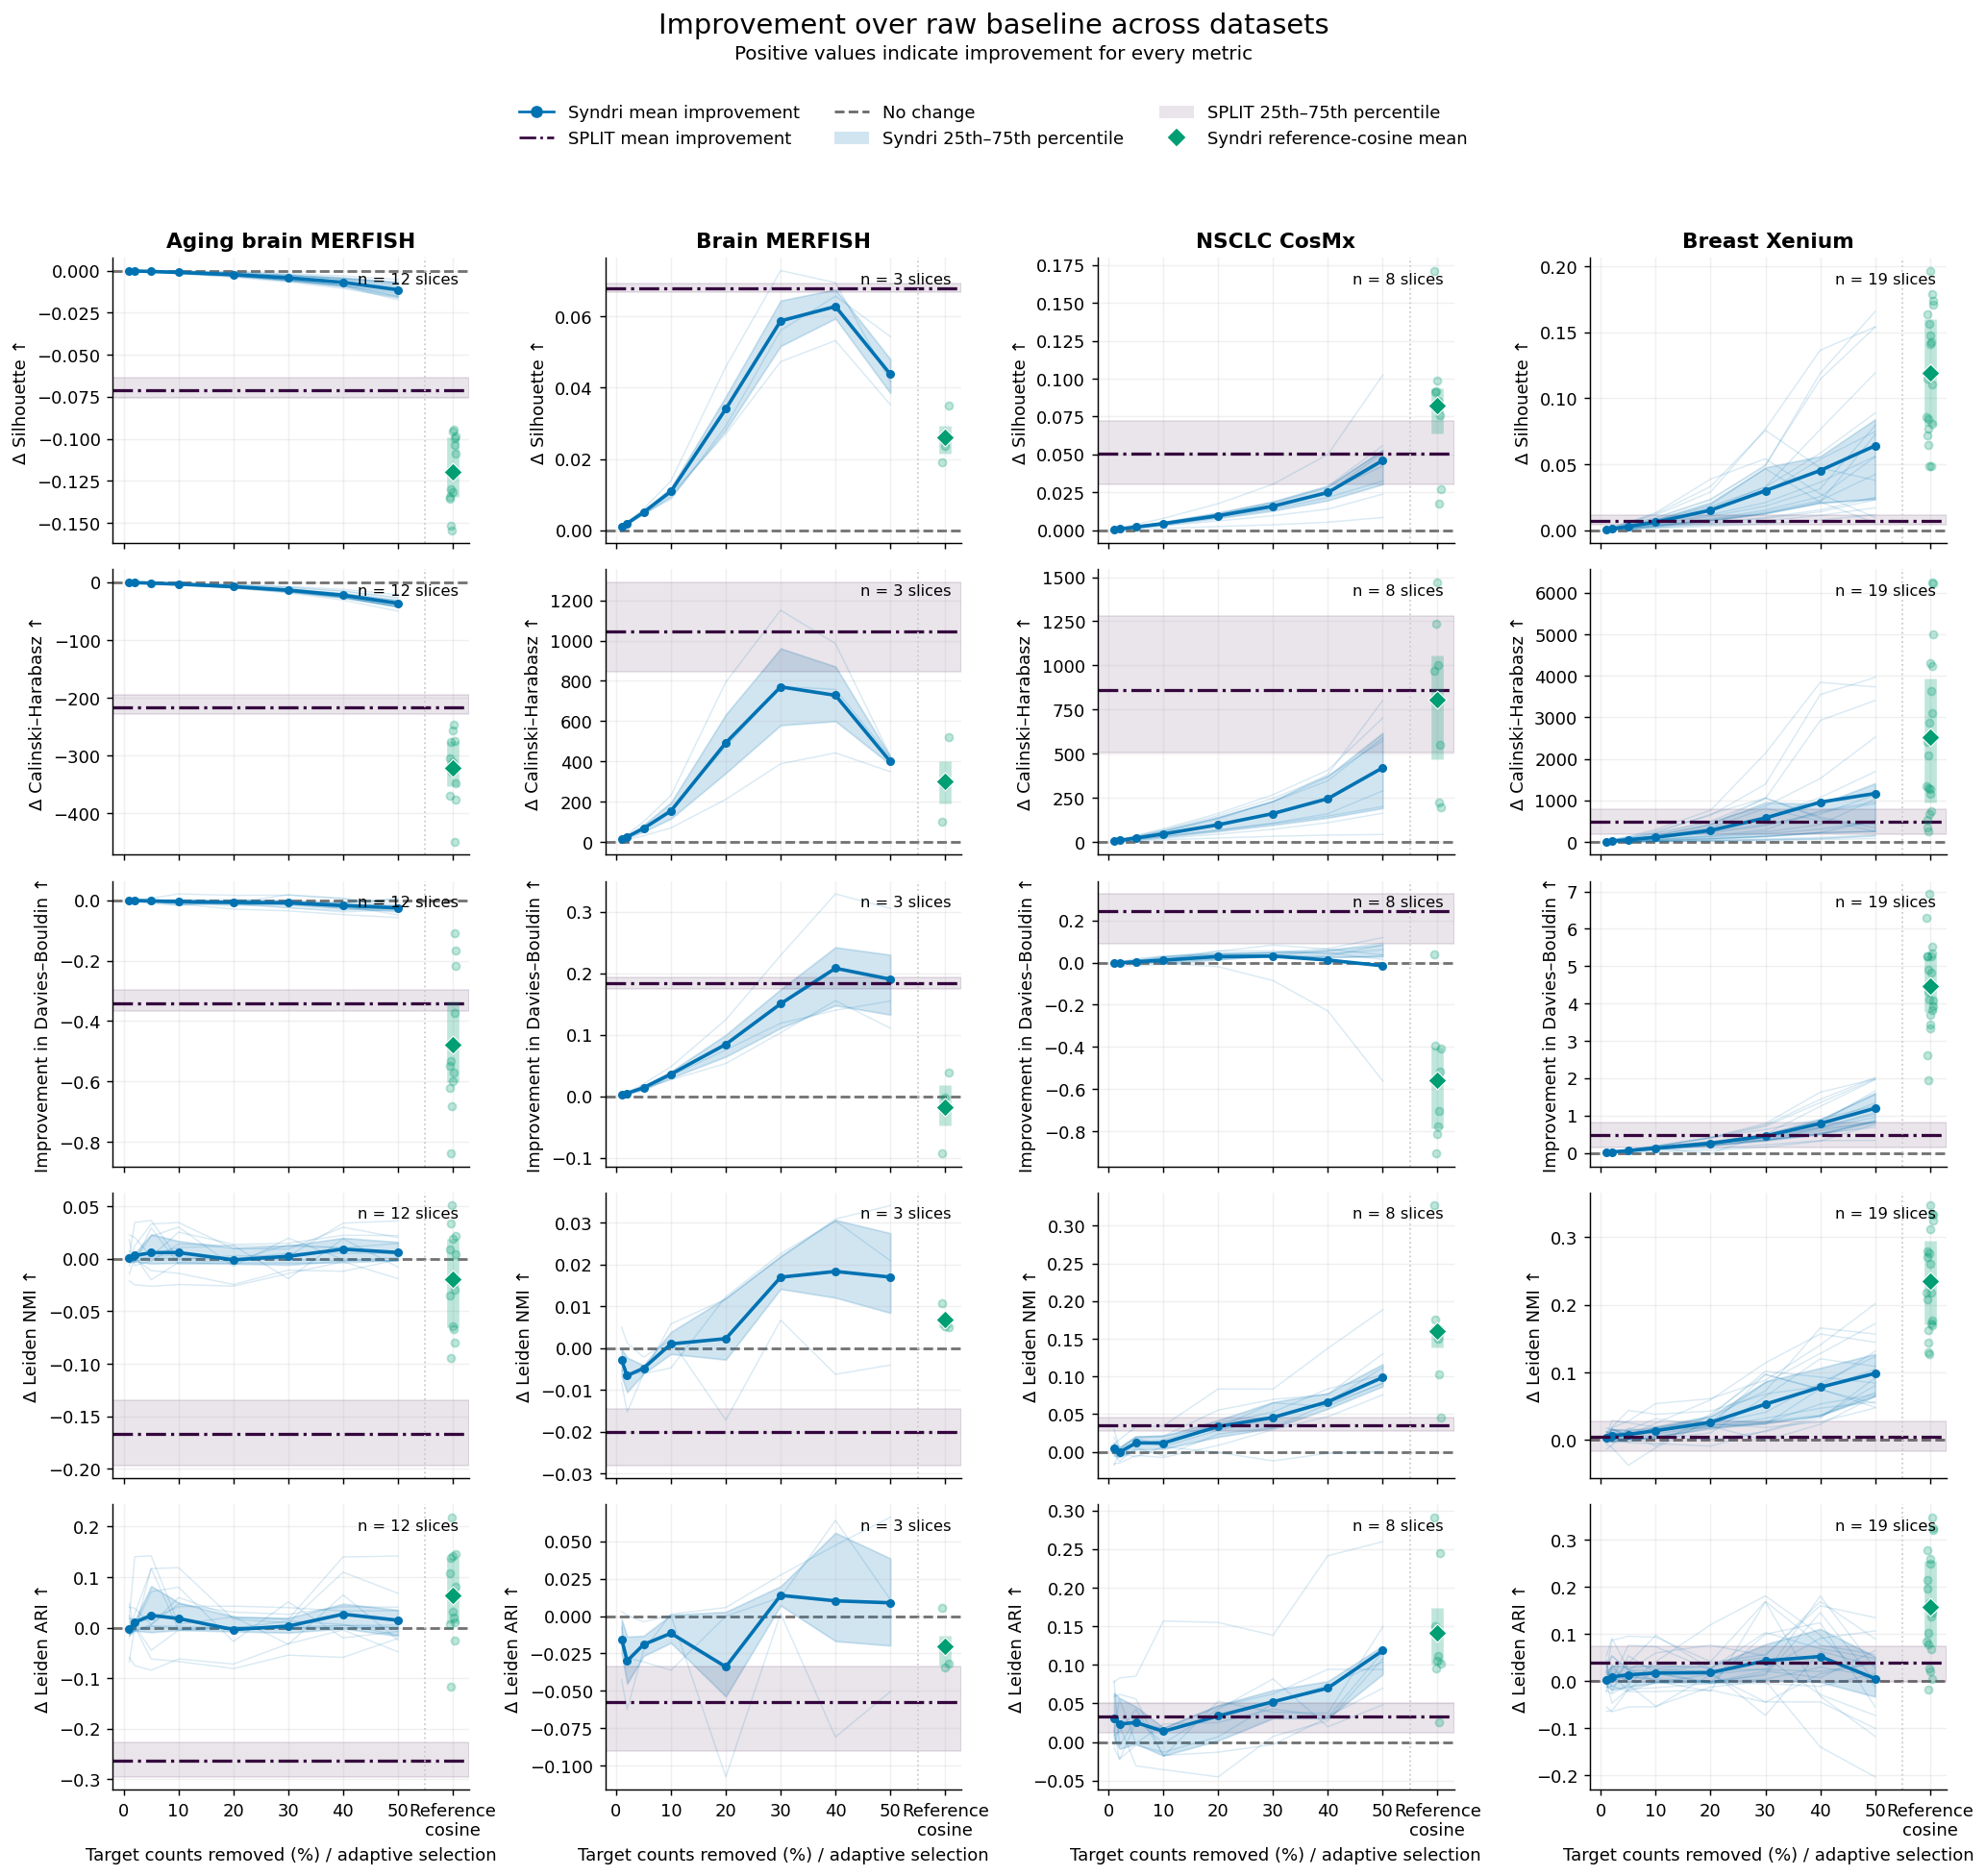

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = metrics.loc[metrics["error"].fillna("").eq("")].copy()
df["target_removed_fraction"] = pd.to_numeric(
    df["target_removed_fraction"], errors="coerce"
)

dataset_titles = {
    "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}

# Direction aligns every metric: positive = improvement over raw.
metric_settings = {
    "silhouette_score": ("Δ Silhouette ↑", 1),
    "calinski_harabasz": ("Δ Calinski–Harabasz ↑", 1),
    "davies_bouldin": ("Improvement in Davies–Bouldin ↑", -1),
    "leiden_nmi_vs_label": ("Δ Leiden NMI ↑", 1),
    "leiden_adjusted_rand_vs_label": ("Δ Leiden ARI ↑", 1),
}

datasets = [d for d in dataset_titles if d in df["dataset"].unique()]
if not datasets:
    raise ValueError("No recognized datasets found.")

syndri_color = "#0072B2"
split_color = "#35063E"
raw_color = "#666666"
adaptive_color = "#009E73"

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        len(metric_settings), len(datasets),
        figsize=(4 * len(datasets), 3 * len(metric_settings)),
        sharex=True,
        squeeze=False,
    )

    for col, dataset in enumerate(datasets):
        subset = df.loc[df["dataset"].eq(dataset)]

        for row, (metric, (title, direction)) in enumerate(
            metric_settings.items()
        ):
            ax = axes[row, col]
            data = subset.copy()
            data[metric] = pd.to_numeric(data[metric], errors="coerce")
            data = data.loc[np.isfinite(data[metric])]

            values = data.pivot_table(
                index="slice",
                columns="case",
                values=metric,
                aggfunc="mean",
            )

            adaptive_case = "syndri_reference_cosine"
            adaptive_x = 60

            sweep = (
                data.loc[
                    data["case"].str.startswith(
                        "cleaned_admixed_removed_frac_", na=False
                    ),
                    ["case", "target_removed_fraction"],
                ]
                .dropna()
                .drop_duplicates()
                .sort_values("target_removed_fraction")
                .drop_duplicates("target_removed_fraction")
            )

            sweep_cases = sweep["case"].tolist()

            required_cases = ["admixed", "SPLIT", adaptive_case, *sweep_cases]
            paired = (
                values[required_cases].dropna()
                if sweep_cases and all(case in values for case in required_cases)
                else pd.DataFrame()
            )

            ax.axhline(
                0,
                color=raw_color,
                linestyle="--",
                linewidth=1.5,
                zorder=1,
            )

            if paired.empty:
                ax.text(
                    0.5,
                    0.5,
                    "Waiting for complete comparisons",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                )
            else:
                # Subtract within each slice before calculating summaries.
                # Davies–Bouldin uses raw − method; others use method − raw.
                improvement = (
                    paired.subtract(paired["admixed"], axis=0) * direction
                )

                x = sweep["target_removed_fraction"].to_numpy() * 100
                y = improvement[sweep_cases].to_numpy()

                split_delta = improvement["SPLIT"].to_numpy()
                adaptive_delta = improvement[adaptive_case].to_numpy()

                # Individual fixed-removal Syndri curves.
                for slice_delta in y:
                    ax.plot(
                        x,
                        slice_delta,
                        color=syndri_color,
                        alpha=0.15,
                        linewidth=0.8,
                    )

                # Fixed-removal Syndri summary.
                ax.fill_between(
                    x,
                    np.quantile(y, 0.25, axis=0),
                    np.quantile(y, 0.75, axis=0),
                    color=syndri_color,
                    alpha=0.18,
                )
                ax.plot(
                    x,
                    y.mean(axis=0),
                    "o-",
                    color=syndri_color,
                    linewidth=2,
                    markersize=4,
                )

                # Per-slice adaptive Syndri results.
                jitter = np.linspace(-0.6, 0.6, len(adaptive_delta))
                ax.scatter(
                    adaptive_x + jitter,
                    adaptive_delta,
                    color=adaptive_color,
                    alpha=0.25,
                    s=20,
                    zorder=3,
                )

                adaptive_q25, adaptive_q75 = np.quantile(
                    adaptive_delta, [0.25, 0.75]
                )
                ax.vlines(
                    adaptive_x,
                    adaptive_q25,
                    adaptive_q75,
                    color=adaptive_color,
                    linewidth=7,
                    alpha=0.25,
                    zorder=4,
                )
                ax.scatter(
                    adaptive_x,
                    adaptive_delta.mean(),
                    color=adaptive_color,
                    marker="D",
                    edgecolor="white",
                    linewidth=0.6,
                    s=55,
                    zorder=5,
                )

                # SPLIT summary.
                ax.axhspan(
                    np.quantile(split_delta, 0.25),
                    np.quantile(split_delta, 0.75),
                    color=split_color,
                    alpha=0.10,
                )
                ax.axhline(
                    split_delta.mean(),
                    color=split_color,
                    linestyle="-.",
                    linewidth=1.8,
                )

                ax.text(
                    0.97,
                    0.95,
                    f"n = {len(paired)} slices",
                    ha="right",
                    va="top",
                    transform=ax.transAxes,
                    fontsize=9,
                )

            ax.grid(alpha=0.18)
            ax.axvline(55, color="0.8", linewidth=1, linestyle=":")

            ax.set_xlim(-2, 63)
            ax.set_xticks([0, 10, 20, 30, 40, 50, adaptive_x])
            ax.set_xticklabels(
                ["0", "10", "20", "30", "40", "50", "Reference\ncosine"]
            )
            ax.set_ylabel(title)

            if row == 0:
                ax.set_title(dataset_titles[dataset])

            if row == len(metric_settings) - 1:
                ax.set_xlabel("Target counts removed (%) / adaptive selection")

    handles = [
        Line2D(
            [0], [0], color=syndri_color, marker="o",
            label="Syndri mean improvement",
        ),
        Line2D(
            [0], [0], color=split_color, linestyle="-.",
            label="SPLIT mean improvement",
        ),
        Line2D(
            [0], [0], color=raw_color, linestyle="--",
            label="No change",
        ),
        Patch(
            facecolor=syndri_color, alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Patch(
            facecolor=split_color, alpha=0.10,
            label="SPLIT 25th–75th percentile",
        ),
        Line2D(
            [0],
            [0],
            color=adaptive_color,
            marker="D",
            linestyle="none",
            label="Syndri reference-cosine mean",
),
    ]

    fig.suptitle(
        "Improvement over raw baseline across datasets",
        y=0.998, fontsize=16,
    )
    fig.text(
        0.5, 0.973,
        "Positive values indicate improvement for every metric",
        ha="center", fontsize=11,
    )
    fig.legend(
        handles=handles, loc="upper center",
        bbox_to_anchor=(0.5, 0.957), ncol=3, frameon=False,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.915])

    # fig.savefig(
    #     "metrics_improvement_from_raw.png",
    #     dpi=300, bbox_inches="tight",
    # )
    # fig.savefig(
    #     "metrics_improvement_from_raw.pdf",
    #     bbox_inches="tight",
    # )
    plt.show()

In [7]:
# Compare each slice's best Syndri result against SPLIT.
# "Best" is selected independently for every slice and metric.

best_rows = []

for dataset in datasets:
    subset = df.loc[df["dataset"].eq(dataset)]

    for metric, (metric_title, direction) in metric_settings.items():
        data = subset.copy()
        data[metric] = pd.to_numeric(data[metric], errors="coerce")
        data = data.loc[np.isfinite(data[metric])]

        if data.empty:
            continue

        # Range across all slices and conditions for this dataset/metric.
        metric_range = data[metric].max() - data[metric].min()

        if not np.isfinite(metric_range) or metric_range <= 0:
            continue

        values = data.pivot_table(
            index="slice",
            columns="case",
            values=metric,
            aggfunc="mean",
        )

        sweep = (
            data.loc[
                data["case"].str.startswith(
                    "cleaned_admixed_removed_frac_", na=False
                ),
                ["case", "target_removed_fraction"],
            ]
            .dropna()
            .drop_duplicates()
            .sort_values("target_removed_fraction")
            .drop_duplicates("target_removed_fraction")
        )

        sweep_cases = sweep["case"].tolist()
        fraction_by_case = dict(
            zip(sweep["case"], sweep["target_removed_fraction"])
        )
        required_cases = ["admixed", "SPLIT", *sweep_cases]

        if (
            not sweep_cases
            or any(case not in values.columns for case in required_cases)
        ):
            continue

        paired = values[required_cases].dropna()

        if paired.empty:
            continue

        # Positive means better than raw for every metric.
        improvement = (
            paired.subtract(paired["admixed"], axis=0) * direction
        )

        for slice_name, row_values in improvement.iterrows():
            best_case = row_values[sweep_cases].idxmax()

            best_syndri = row_values[best_case]
            split = row_values["SPLIT"]

            best_rows.append({
                "dataset": dataset,
                "slice": slice_name,
                "metric": metric,
                "metric_title": metric_title.replace("Δ ", ""),
                "metric_range": metric_range,
                "best_syndri_improvement": best_syndri,
                "split_improvement": split,
                "best_syndri_minus_split": best_syndri - split,
                "best_removed_fraction": fraction_by_case[best_case],
                "best_removed_percent": (
                    fraction_by_case[best_case] * 100
                ),
            })

best_comparison = pd.DataFrame(best_rows)

# Express each improvement as a fraction of the observed metric range.
best_comparison_normalized = best_comparison.copy()

columns_to_normalize = [
    "best_syndri_improvement",
    "split_improvement",
    "best_syndri_minus_split",
]

best_comparison_normalized[columns_to_normalize] = (
    best_comparison_normalized[columns_to_normalize]
    .div(best_comparison_normalized["metric_range"], axis=0)
)

display(
    best_comparison_normalized.sort_values(
        ["dataset", "metric", "slice"]
    ).head()
)

,dataset,slice,metric,metric_title,metric_range,best_syndri_improvement,split_improvement,best_syndri_minus_split,best_removed_fraction,best_removed_percent
12,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,calinski_harabasz,Calinski–Harabasz ↑,638.066547,-0.000526,-0.350125,0.349599,0.01,1.0
13,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_1,calinski_harabasz,Calinski–Harabasz ↑,638.066547,-0.000549,-0.276481,0.275932,0.01,1.0
14,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_2,calinski_harabasz,Calinski–Harabasz ↑,638.066547,-0.000393,-0.241440,0.241047,0.01,1.0
15,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_0,calinski_harabasz,Calinski–Harabasz ↑,638.066547,-0.000530,-0.321004,0.320474,0.01,1.0
16,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_1,calinski_harabasz,Calinski–Harabasz ↑,638.066547,-0.000578,-0.342741,0.342164,0.01,1.0


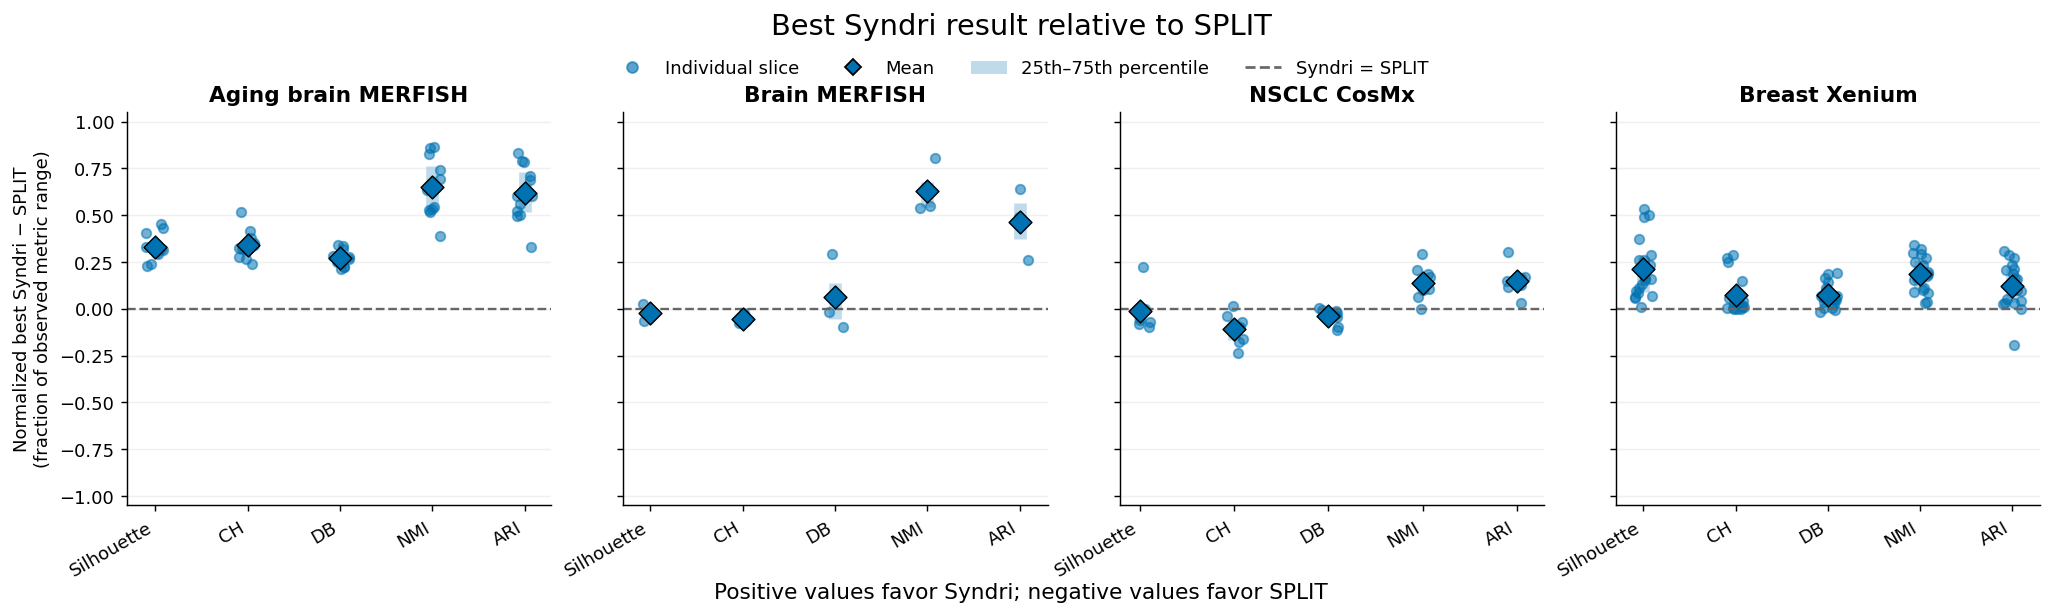

In [ ]:
dataset_order = datasets
metric_order = list(metric_settings)

metric_labels = {
    "silhouette_score": "Silhouette",
    "calinski_harabasz": "CH",
    "davies_bouldin": "DB",
    "leiden_nmi_vs_label": "NMI",
    "leiden_adjusted_rand_vs_label": "ARI",
}

best_color = "#0072B2"
zero_color = "#666666"
rng = np.random.default_rng(0)

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        1,
        len(dataset_order),
        figsize=(4 * len(dataset_order), 4.8),
        sharey=True,
        squeeze=False,
        # constrained_layout=True,
    )

    for col, dataset in enumerate(dataset_order):
        ax = axes[0, col]

        plot_data = best_comparison_normalized.loc[
            best_comparison_normalized["dataset"].eq(dataset)
        ].copy()

        positions = np.arange(len(metric_order))

        for position, metric in zip(positions, metric_order):
            values = plot_data.loc[
                plot_data["metric"].eq(metric),
                "best_syndri_minus_split",
            ].dropna()

            if values.empty:
                continue

            jitter = rng.uniform(-0.10, 0.10, len(values))

            # Individual slices.
            ax.scatter(
                np.full(len(values), position) + jitter,
                values,
                color=best_color,
                alpha=0.55,
                s=28,
                zorder=2,
            )

            # Interquartile range.
            ax.vlines(
                position,
                values.quantile(0.25),
                values.quantile(0.75),
                color=best_color,
                linewidth=7,
                alpha=0.25,
                zorder=1,
            )

            # Mean.
            ax.scatter(
                position,
                values.mean(),
                color=best_color,
                edgecolor="black",
                marker="D",
                s=80,
                linewidth=0.8,
                zorder=3,
            )

        ax.axhline(
            0,
            color=zero_color,
            linestyle="--",
            linewidth=1.3,
        )

        ax.set_xticks(positions)
        ax.set_xticklabels(
            [metric_labels[m] for m in metric_order],
            rotation=30,
            ha="right",
        )
        ax.set_title(dataset_titles[dataset])
        ax.set_ylim(-1.05, 1.05)
        ax.set_yticks(np.arange(-1, 1.01, 0.25))
        ax.grid(axis="y", alpha=0.18)

        if col == 0:
            ax.set_ylabel(
                "Normalized best Syndri − SPLIT\n"
                "(fraction of observed metric range)"
            )

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=best_color,
            alpha=0.65,
            label="Individual slice",
        ),
        Line2D(
            [0], [0],
            marker="D",
            markeredgecolor="black",
            linestyle="",
            color=best_color,
            label="Mean",
        ),
        Patch(
            facecolor=best_color,
            alpha=0.25,
            label="25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=zero_color,
            linestyle="--",
            label="Syndri = SPLIT",
        ),
    ]

    fig.suptitle(
    "Best Syndri result relative to SPLIT",
    fontsize=16,
    y=0.98,
)

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=4,
    frameon=False,
)

fig.supxlabel(
    "Positive values favor Syndri; negative values favor SPLIT",
    y=0.035,
)

# Reserve explicit space for the title, legend, and bottom caption.
fig.subplots_adjust(
    top=0.82,
    bottom=0.19,
    left=0.07,
    right=0.99,
    wspace=0.17,
)

# fig.savefig(
#     "best_syndri_vs_split_normalized.png",
#     dpi=300,
#     bbox_inches="tight",
# )
# fig.savefig(
#     "best_syndri_vs_split_normalized.pdf",
#     bbox_inches="tight",
# )
plt.show()


In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

root = Path("/work/magroup/skrieger/Syndri/data/datasets")

dataset_titles = {
    "breast_xenium": "Breast Xenium",
    "nsclc_cosmx": "NSCLC CosMx",
}

result_types = {
    "contamination": "tcell_contamination_metrics.csv",
    "effects": "tcell_contamination_effects.csv",
    "cosine": "tcell_cosine_similarity.csv",
    "genes": "tcell_lr_top_genes.csv",
    "profiles": "tissue_cell_type_profiles.csv",
}


def load_tcell_results(result_type):
    filename = result_types[result_type]
    frames = []

    for dataset in dataset_titles:
        search_root = root / dataset / "results/metrics/tcell"

        for path in sorted(search_root.glob(f"*/{filename}")):
            if path.stat().st_size == 0:
                continue

            try:
                frame = pd.read_csv(path)
            except pd.errors.EmptyDataError:
                continue

            frame["dataset"] = dataset
            frame["slice"] = path.parent.name
            frame["result_path"] = str(path)
            frames.append(frame)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


tcell_contamination = load_tcell_results("contamination")
tcell_effects = load_tcell_results("effects")
tcell_cosine = load_tcell_results("cosine")
tcell_genes = load_tcell_results("genes")
tcell_profiles = load_tcell_results("profiles")

print("Loaded rows:")
print("  contamination:", len(tcell_contamination))
print("  effects:", len(tcell_effects))
print("  cosine:", len(tcell_cosine))
print("  genes:", len(tcell_genes))
print("  profiles:", len(tcell_profiles))

print("\nCompleted slices:")
for dataset in dataset_titles:
    n = tcell_contamination.loc[
        tcell_contamination["dataset"].eq(dataset), "slice"
    ].nunique()
    print(f"  {dataset}: {n}")

ADAPTIVE_CONDITION = "syndri_reference_cosine"


def valid_rows(frame):
    if frame.empty:
        return frame.copy()

    result = frame.copy()

    if "error" in result.columns:
        result = result.loc[
            result["error"].fillna("").astype(str).eq("")
        ].copy()

    if "condition" not in result.columns:
        result["condition"] = ""
    else:
        result["condition"] = result["condition"].fillna("").astype(str)

    if "target_removed_fraction" in result.columns:
        result["target_removed_fraction"] = pd.to_numeric(
            result["target_removed_fraction"],
            errors="coerce",
        )
    else:
        result["target_removed_fraction"] = np.nan

    # Identify the different correction strategies without requiring every
    # case to have a target_removed_fraction.
    result["is_raw"] = result["condition"].eq("raw_X")
    result["is_split"] = result["condition"].eq("SPLIT")
    result["is_syndri_reference_cosine"] = result["condition"].eq(
        ADAPTIVE_CONDITION
    )
    result["is_syndri_fixed_removal"] = (
        result["condition"].str.startswith(
            "cleaned_admixed_removed_frac_",
            na=False,
        )
        & result["target_removed_fraction"].notna()
    )

    result["method"] = np.select(
        [
            result["is_raw"],
            result["is_split"],
            result["is_syndri_reference_cosine"],
            result["is_syndri_fixed_removal"],
        ],
        [
            "Raw",
            "SPLIT",
            "Syndri reference cosine",
            "Syndri fixed removal",
        ],
        default=result["condition"],
    )

    # Numeric position used by the plots:
    # 0–0.5 are fixed-removal fractions; 0.6 is adaptive Syndri.
    result["plot_position"] = result["target_removed_fraction"]
    result.loc[
        result["is_syndri_reference_cosine"],
        "plot_position",
    ] = 0.60

    return result


def paired_improvement(
    frame,
    value_col,
    pair_cols,
    direction=1,
    raw_case="raw_X",
):
    """
    direction=1:  larger values are better
    direction=-1: smaller values are better

    Positive improvement always means better than raw.
    Adaptive Syndri rows are retained despite having no target-removal fraction.
    """
    data = valid_rows(frame)

    if data.empty:
        return data

    required = {"condition", value_col, *pair_cols}
    missing = required.difference(data.columns)
    if missing:
        raise KeyError(
            f"Missing columns required for pairing: {sorted(missing)}"
        )

    data[value_col] = pd.to_numeric(
        data[value_col],
        errors="coerce",
    )
    data = data.loc[np.isfinite(data[value_col])].copy()

    raw = (
        data.loc[
            data["condition"].eq(raw_case),
            pair_cols + [value_col],
        ]
        .groupby(pair_cols, observed=True, dropna=False)[value_col]
        .mean()
        .rename("raw_value")
        .reset_index()
    )

    if raw.empty:
        raise ValueError(
            f"No {raw_case!r} rows were found for {value_col!r}."
        )

    paired = data.merge(
        raw,
        on=pair_cols,
        how="inner",
        validate="many_to_one",
    )

    paired["improvement_from_raw"] = (
        paired[value_col] - paired["raw_value"]
    ) * direction

    return paired

contamination_delta = paired_improvement(
    tcell_contamination,
    value_col="marker_overlap_frac",
    pair_cols=[
        "dataset",
        "slice",
        "target_cell_type_i",
        "contaminating_cell_type_j",
    ],
    direction=-1,  # Less contaminating-marker overlap is better.
)

cosine_delta = paired_improvement(
    tcell_cosine,
    value_col="cosine_similarity",
    pair_cols=[
        "dataset",
        "slice",
        "spatial_cell_type",
        "reference_cell_type",
    ],
    direction=1,  # Greater reference similarity is better.
)

/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (15,18,19,20,26) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (18,19,20,23,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (18,19,20,23,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (23,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (23,25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_2365892/685215531.py:37: DtypeWarning: Columns (18,19,20,23,25,26) have mixed types. S

Loaded rows:
  contamination: 48790
  effects: 4421
  cosine: 1152
  genes: 1153153
  profiles: 2753715

Completed slices:
  breast_xenium: 19
  nsclc_cosmx: 16


In [28]:
cosine_delta = cosine_delta[~cosine_delta['tissue'].str.startswith('cosmx_nsclc')&(cosine_delta['threshold_selection']!='per_cell_rolling_reference_cosine')]

In [29]:
cosine_delta['threshold_selection'].unique()

array([nan, 'cell_type_smallest_near_optimal_k'], dtype=object)

In [30]:
for name, table in {
    "contamination": contamination_delta,
    "cosine": cosine_delta,
}.items():
    counts = (
        table.groupby(["dataset", "condition"], dropna=False)
        .size()
        .unstack(fill_value=0)
    )
    print(f"\n{name}")
    print(counts)

    adaptive = table.loc[
        table["condition"].eq("syndri_reference_cosine")
    ]
    print("Adaptive rows:", len(adaptive))
    print("Adaptive slices:", adaptive["slice"].nunique())


contamination
condition      SPLIT  cleaned_admixed_removed_frac_0.01  \
dataset                                                   
breast_xenium   3011                               3011   
nsclc_cosmx     1410                               1410   

condition      cleaned_admixed_removed_frac_0.02  \
dataset                                            
breast_xenium                               3011   
nsclc_cosmx                                 1410   

condition      cleaned_admixed_removed_frac_0.05  \
dataset                                            
breast_xenium                               3011   
nsclc_cosmx                                 1410   

condition      cleaned_admixed_removed_frac_0.1  \
dataset                                           
breast_xenium                              3011   
nsclc_cosmx                                1410   

condition      cleaned_admixed_removed_frac_0.2  \
dataset                                           
breast_xenium          

In [73]:
cosine_delta.columns

Index(['tissue', 'source_file', 'condition', 'spatial_counts_layer',
       'reference_counts_layer', 'reference_cell_type_key',
       'cosine_similarity', 'n_spatial_cells', 'n_reference_cells',
       'n_shared_genes', 'spatial_cell_type', 'reference_cell_type', 'error',
       'target_removed_fraction', 'admix_prob_threshold',
       'achieved_removed_fraction', 'cleaning_mode', 'probability_transform',
       'probability_removal_scale', 'cell_type_specific_removal',
       'group_admix_prob_thresholds', 'group_probability_removal_scales',
       'group_achieved_removed_fractions', 'threshold_selection',
       'cosine_window', 'reference_profiles', 'syndri_probability_ordering',
       'syndri_min_removal_probability', 'dataset', 'slice', 'result_path',
       'syndri_one_se_multiplier', 'is_raw', 'is_split',
       'is_syndri_reference_cosine', 'is_syndri_fixed_removal', 'method',
       'plot_position', 'raw_value', 'improvement_from_raw'],
      dtype='object')

In [77]:
cosine_delta[(cosine_delta['dataset']=='breast_xenium')&(cosine_delta['condition']=='syndri_reference_cosine')].groupby(['tissue','spatial_cell_type'])['improvement_from_raw'].min()

tissue                                           spatial_cell_type                     
GSM9509156_breast_breast_B17_B17_rctd_annotated  CD4-positive, alpha-beta memory T cell    0.103205
                                                 cytotoxic T cell                          0.111056
                                                 natural T-regulatory cell                 0.097866
GSM9509157_breast_breast_B16_B16_rctd_annotated  CD4-positive, alpha-beta memory T cell    0.065678
                                                 cytotoxic T cell                          0.054990
                                                 natural T-regulatory cell                 0.055588
GSM9509158_breast_breast_B15_B15_rctd_annotated  CD4-positive, alpha-beta memory T cell    0.095735
                                                 cytotoxic T cell                          0.105184
                                                 natural T-regulatory cell                 0.090898
GSM9509159_b

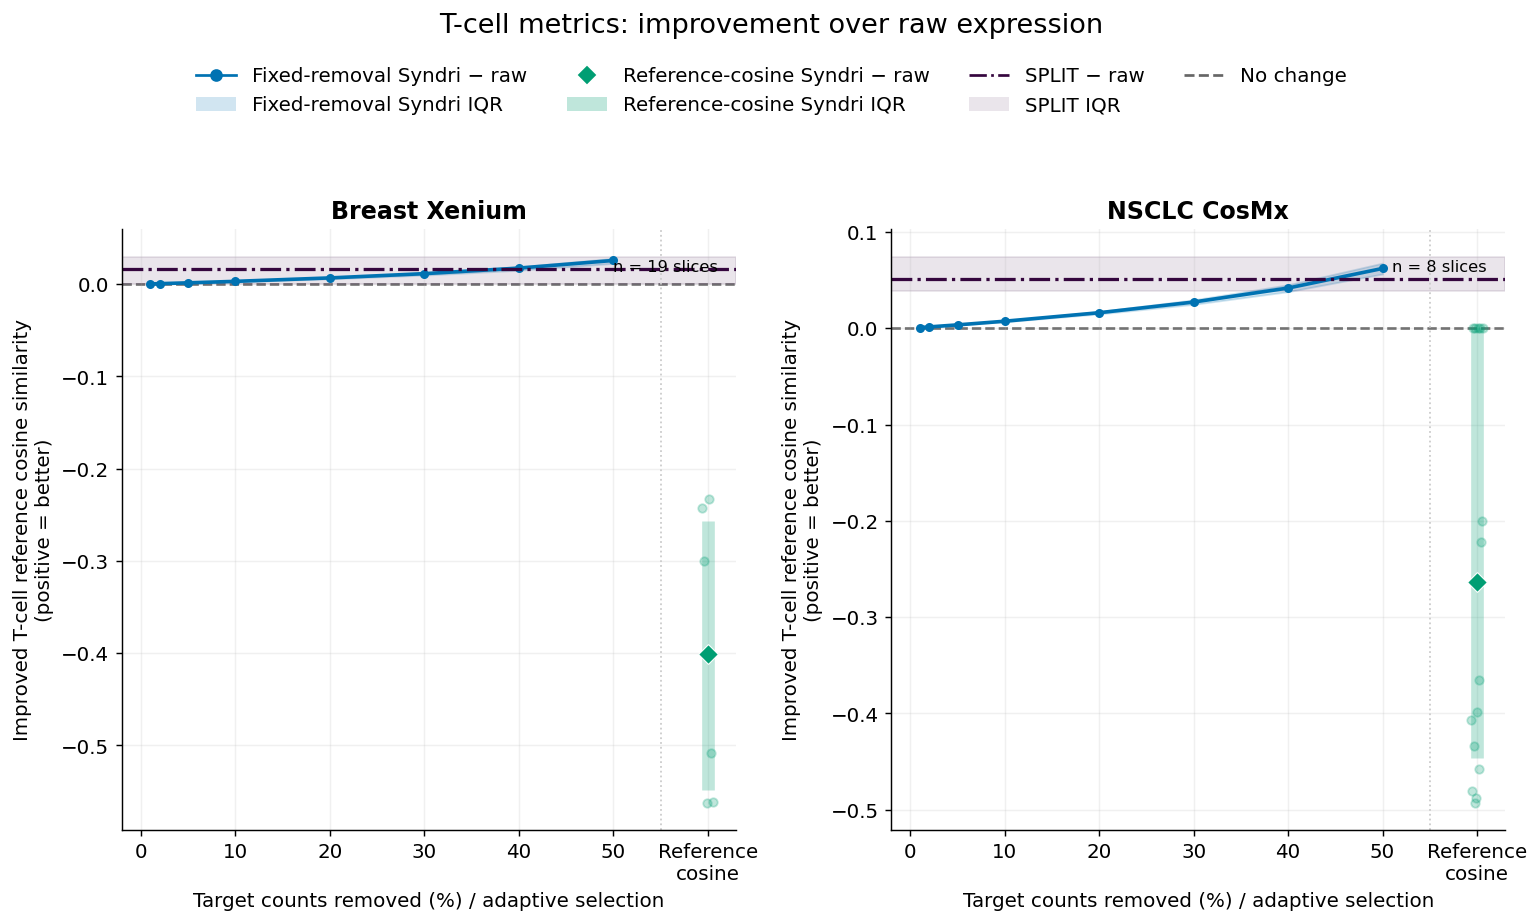

In [31]:
syndri_color = "#0072B2"
adaptive_color = "#009E73"
split_color = "#35063E"
zero_color = "#666666"

adaptive_condition = "syndri_reference_cosine"
adaptive_x = 60

metric_specs = [
    (
        cosine_delta,
        "Improved T-cell reference cosine similarity",
    ),
]

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        nrows=len(metric_specs),
        ncols=len(dataset_titles),
        figsize=(12, 7),
        sharex=True,
        squeeze=False,
    )

    for col, (dataset, dataset_title) in enumerate(dataset_titles.items()):
        for row, (table, ylabel) in enumerate(metric_specs):
            ax = axes[row, col]
            subset = table.loc[table["dataset"].eq(dataset)].copy()

            ax.axhline(
                0,
                color=zero_color,
                linestyle="--",
                linewidth=1.4,
                zorder=1,
            )

            # Fixed-removal Syndri cases.
            syndri = subset.loc[
                subset["condition"].str.startswith(
                    "cleaned_admixed_removed_frac_", na=False
                )
                & subset["target_removed_fraction"].notna()
            ].copy()

            summary = (
                syndri.groupby("target_removed_fraction", observed=True)
                ["improvement_from_raw"]
                .agg(
                    mean="mean",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                    n="size",
                )
                .reset_index()
                .sort_values("target_removed_fraction")
            )

            if not summary.empty:
                x = summary["target_removed_fraction"].to_numpy() * 100

                ax.fill_between(
                    x,
                    summary["q25"].to_numpy(),
                    summary["q75"].to_numpy(),
                    color=syndri_color,
                    alpha=0.18,
                )
                ax.plot(
                    x,
                    summary["mean"].to_numpy(),
                    "o-",
                    color=syndri_color,
                    linewidth=2,
                    markersize=4,
                )

            # Adaptive per-cell reference-cosine Syndri case.
            adaptive = subset.loc[
                subset["condition"].eq(adaptive_condition),
                ["slice", "improvement_from_raw"],
            ].dropna()

            if not adaptive.empty:
                adaptive_values = adaptive["improvement_from_raw"]

                # Faint marks show individual slices.
                jitter = np.linspace(
                    -0.6, 0.6, len(adaptive_values)
                )
                ax.scatter(
                    adaptive_x + jitter,
                    adaptive_values,
                    color=adaptive_color,
                    alpha=0.25,
                    s=22,
                    zorder=3,
                )

                # Thick vertical segment shows the interquartile range.
                ax.vlines(
                    adaptive_x,
                    adaptive_values.quantile(0.25),
                    adaptive_values.quantile(0.75),
                    color=adaptive_color,
                    linewidth=7,
                    alpha=0.25,
                    zorder=4,
                )

                # Diamond shows the mean across slices.
                ax.scatter(
                    adaptive_x,
                    adaptive_values.mean(),
                    color=adaptive_color,
                    marker="D",
                    edgecolor="white",
                    linewidth=0.6,
                    s=60,
                    zorder=5,
                )

            # SPLIT is independent of the Syndri removal fraction.
            split = subset.loc[
                subset["condition"].eq("SPLIT"),
                "improvement_from_raw",
            ].dropna()

            if not split.empty:
                ax.axhspan(
                    split.quantile(0.25),
                    split.quantile(0.75),
                    color=split_color,
                    alpha=0.10,
                )
                ax.axhline(
                    split.mean(),
                    color=split_color,
                    linestyle="-.",
                    linewidth=1.8,
                )

            # Separate the adaptive result from the numeric percentage scale.
            ax.axvline(
                55,
                color="0.8",
                linestyle=":",
                linewidth=1,
            )

            n_slices = subset["slice"].nunique()
            ax.text(
                0.97,
                0.95,
                f"n = {n_slices} slices",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9,
            )

            if row == 0:
                ax.set_title(dataset_title)

            ax.set_ylabel(ylabel + "\n(positive = better)")
            ax.set_xlim(-2, 63)
            # ax.set_ylim(0,0.15)
            ax.set_xticks([0, 10, 20, 30, 40, 50, adaptive_x])
            ax.set_xticklabels([
                "0", "10", "20", "30", "40", "50",
                "Reference\ncosine",
            ])
            ax.grid(alpha=0.18)

            if row == len(metric_specs) - 1:
                ax.set_xlabel(
                    "Target counts removed (%) / adaptive selection"
                )

    legend = [
        Line2D(
            [0], [0],
            color=syndri_color,
            marker="o",
            label="Fixed-removal Syndri − raw",
        ),
        Patch(
            facecolor=syndri_color,
            alpha=0.18,
            label="Fixed-removal Syndri IQR",
        ),
        Line2D(
            [0], [0],
            color=adaptive_color,
            marker="D",
            linestyle="none",
            label="Reference-cosine Syndri − raw",
        ),
        Patch(
            facecolor=adaptive_color,
            alpha=0.25,
            label="Reference-cosine Syndri IQR",
        ),
        Line2D(
            [0], [0],
            color=split_color,
            linestyle="-.",
            label="SPLIT − raw",
        ),
        Patch(
            facecolor=split_color,
            alpha=0.10,
            label="SPLIT IQR",
        ),
        Line2D(
            [0], [0],
            color=zero_color,
            linestyle="--",
            label="No change",
        ),
    ]

    fig.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=4,
        frameon=False,
    )
    fig.suptitle(
        "T-cell metrics: improvement over raw expression",
        y=1.01,
        fontsize=15,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.88])

    plt.show()

In [33]:
n_adaptive = (
    adaptive.groupby("dataset", observed=True)["slice"]
    .nunique()
    .to_dict()
)

# Inside the dataset plotting loop:
n = n_adaptive.get(dataset, 0)
ax.text(
    0.97,
    0.95,
    f"Reference cosine: n = {n} slices",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
)


Text(0.97, 0.95, 'Reference cosine: n = 5 slices')

In [32]:
adaptive = cosine_delta.loc[
    cosine_delta["condition"].eq("syndri_reference_cosine")
    & cosine_delta["threshold_selection"].eq(
        "cell_type_smallest_near_optimal_k"
    )
].copy()

adaptive.groupby("dataset")["slice"].nunique()


dataset
breast_xenium    2
nsclc_cosmx      5
Name: slice, dtype: int64

In [21]:
poor = cosine_delta.loc[
    cosine_delta["condition"].eq("syndri_reference_cosine")
    & cosine_delta["improvement_from_raw"].lt(0)
]

poor[
    [
        "dataset",
        "slice",
        "spatial_cell_type",
        "reference_cell_type",
        "improvement_from_raw",
    ]
].sort_values("improvement_from_raw")

adaptive = cosine_delta.loc[
    cosine_delta["condition"].eq("syndri_reference_cosine")
    & cosine_delta["threshold_selection"].eq(
        "cell_type_smallest_near_optimal_k"
    )
]
adaptive

,tissue,source_file,condition,spatial_counts_layer,reference_counts_layer,reference_cell_type_key,cosine_similarity,n_spatial_cells,n_reference_cells,n_shared_genes,...,result_path,syndri_one_se_multiplier,is_raw,is_split,is_syndri_reference_cosine,is_syndri_fixed_removal,method,plot_position,raw_value,improvement_from_raw
594,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.621038,4026,339,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.863600,-0.242563
595,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.573093,6826,573,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.873161,-0.300068
596,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.289204,2133,252,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.851508,-0.562305
630,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.626813,3160,339,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.859185,-0.232372
631,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.361527,5107,573,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.869715,-0.508189
632,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,/work/magroup/skrieger/Syndri/data/datasets/br...,syndri_reference_cosine,X,X,cell_type,0.289158,1692,252,277,...,/work/magroup/skrieger/Syndri/data/datasets/br...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.850986,-0.561828
1005,st_integrated_slice-Lung5_Rep2,/work/magroup/skrieger/Syndri/data/datasets/ns...,syndri_reference_cosine,X,X,cell_type_harmonized,0.372026,9769,9374,956,...,/work/magroup/skrieger/Syndri/data/datasets/ns...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.779298,-0.407272
1006,st_integrated_slice-Lung5_Rep2,/work/magroup/skrieger/Syndri/data/datasets/ns...,syndri_reference_cosine,X,X,cell_type_harmonized,0.297995,1963,3383,956,...,/work/magroup/skrieger/Syndri/data/datasets/ns...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.778597,-0.480602
1007,st_integrated_slice-Lung5_Rep2,/work/magroup/skrieger/Syndri/data/datasets/ns...,syndri_reference_cosine,X,X,cell_type_harmonized,0.722797,64,19,956,...,/work/magroup/skrieger/Syndri/data/datasets/ns...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.722797,0.000000
1041,st_integrated_slice-Lung5_Rep3,/work/magroup/skrieger/Syndri/data/datasets/ns...,syndri_reference_cosine,X,X,cell_type_harmonized,0.372410,8905,9374,956,...,/work/magroup/skrieger/Syndri/data/datasets/ns...,1.0,False,False,True,False,Syndri reference cosine,0.6,0.806273,-0.433863


In [18]:
summary = (
    diagnostics.groupby(["dataset", "slice", "cell_type"], observed=True)
    .agg(
        n_cells=("cell_id", "size"),
        selected_k=("selected_k", "first"),
        k_max=("k_max", "first"),
        mean_genes_removed=("n_removed_genes", "mean"),
        median_genes_removed=("n_removed_genes", "median"),
        mean_transcripts_removed=("removed_count", "mean"),
        total_transcripts_removed=("removed_count", "sum"),
        total_original_counts=("original_count", "sum"),
    )
    .reset_index()
)

summary["transcript_fraction_removed"] = (
    summary["total_transcripts_removed"]
    / summary["total_original_counts"]
)

KeyError: "Column(s) ['k_max', 'selected_k'] do not exist"

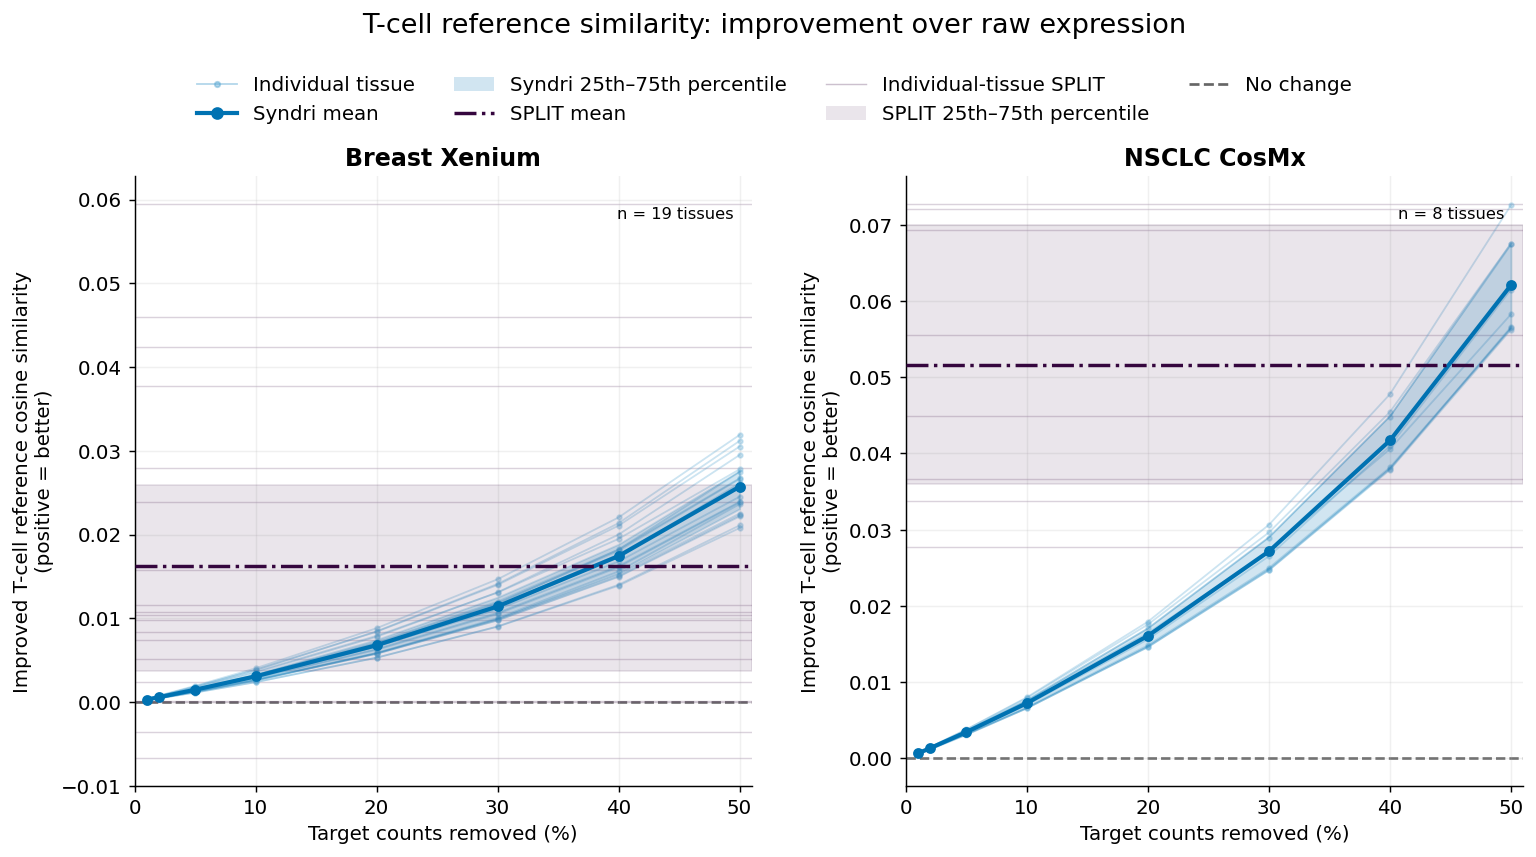

In [79]:
syndri_color = "#0072B2"
split_color = "#35063E"
zero_color = "#666666"
tissue_color = "#56A6D2"

metric_specs = [
    (
        cosine_delta,
        "Improved T-cell reference cosine similarity",
    ),
]

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        nrows=len(metric_specs),
        ncols=len(dataset_titles),
        figsize=(12, 7),
        sharex=True,
        squeeze=False,
    )

    for col, (dataset, dataset_title) in enumerate(dataset_titles.items()):
        for row, (table, ylabel) in enumerate(metric_specs):
            ax = axes[row, col]

            subset = table.loc[
                table["dataset"].eq(dataset)
            ].copy()

            ax.axhline(
                0,
                color=zero_color,
                linestyle="--",
                linewidth=1.4,
                zorder=1,
            )

            # Syndri removal-fraction cases.
            syndri = subset.loc[
                subset["condition"].str.startswith(
                    "cleaned_admixed_removed_frac_",
                    na=False,
                )
                & subset["target_removed_fraction"].notna()
            ].copy()

            # Average across T-cell subtypes within each tissue.
            # This gives every tissue one value per removal fraction.
            tissue_syndri = (
                syndri.groupby(
                    ["slice", "target_removed_fraction"],
                    observed=True,
                    as_index=False,
                )["improvement_from_raw"]
                .mean()
                .sort_values(
                    ["slice", "target_removed_fraction"]
                )
            )

            # Plot one faint trajectory per tissue.
            for tissue, tissue_data in tissue_syndri.groupby(
                "slice",
                observed=True,
            ):
                tissue_data = tissue_data.sort_values(
                    "target_removed_fraction"
                )

                ax.plot(
                    tissue_data["target_removed_fraction"] * 100,
                    tissue_data["improvement_from_raw"],
                    color=tissue_color,
                    alpha=0.30,
                    linewidth=1.0,
                    marker="o",
                    markersize=2.5,
                    zorder=2,
                )

            # Summarize across tissues, giving every tissue equal weight.
            summary = (
                tissue_syndri.groupby(
                    "target_removed_fraction",
                    observed=True,
                )["improvement_from_raw"]
                .agg(
                    mean="mean",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                    n="size",
                )
                .reset_index()
                .sort_values("target_removed_fraction")
            )

            if not summary.empty:
                x = (
                    summary["target_removed_fraction"].to_numpy()
                    * 100
                )

                ax.fill_between(
                    x,
                    summary["q25"].to_numpy(),
                    summary["q75"].to_numpy(),
                    color=syndri_color,
                    alpha=0.18,
                    zorder=3,
                )

                ax.plot(
                    x,
                    summary["mean"].to_numpy(),
                    "o-",
                    color=syndri_color,
                    linewidth=2.3,
                    markersize=5,
                    zorder=4,
                )

            # Average SPLIT across T-cell subtypes within each tissue.
            tissue_split = (
                subset.loc[
                    subset["condition"].eq("SPLIT")
                ]
                .groupby("slice", observed=True)
                ["improvement_from_raw"]
                .mean()
                .dropna()
            )

            if not tissue_split.empty:
                # Individual tissue-specific SPLIT values.
                for split_value in tissue_split:
                    ax.axhline(
                        split_value,
                        color=split_color,
                        alpha=0.18,
                        linewidth=0.8,
                        zorder=1,
                    )

                # SPLIT interquartile range.
                ax.axhspan(
                    tissue_split.quantile(0.25),
                    tissue_split.quantile(0.75),
                    color=split_color,
                    alpha=0.10,
                    zorder=2,
                )

                # SPLIT mean.
                ax.axhline(
                    tissue_split.mean(),
                    color=split_color,
                    linestyle="-.",
                    linewidth=1.9,
                    zorder=4,
                )

            n_slices = tissue_syndri["slice"].nunique()

            ax.text(
                0.97,
                0.95,
                f"n = {n_slices} tissues",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9,
            )

            if row == 0:
                ax.set_title(dataset_title)

            ax.set_ylabel(
                ylabel + "\n(positive = better)"
            )
            ax.set_xlim(0, 51)
            ax.set_xticks([0, 10, 20, 30, 40, 50])
            ax.grid(alpha=0.18)

            if row == len(metric_specs) - 1:
                ax.set_xlabel("Target counts removed (%)")

    legend = [
        Line2D(
            [0], [0],
            color=tissue_color,
            marker="o",
            linewidth=1,
            markersize=3,
            alpha=0.45,
            label="Individual tissue",
        ),
        Line2D(
            [0], [0],
            color=syndri_color,
            marker="o",
            linewidth=2.3,
            label="Syndri mean",
        ),
        Patch(
            facecolor=syndri_color,
            alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=split_color,
            linestyle="-.",
            linewidth=1.9,
            label="SPLIT mean",
        ),
        Line2D(
            [0], [0],
            color=split_color,
            linewidth=0.8,
            alpha=0.25,
            label="Individual-tissue SPLIT",
        ),
        Patch(
            facecolor=split_color,
            alpha=0.10,
            label="SPLIT 25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=zero_color,
            linestyle="--",
            label="No change",
        ),
    ]

    fig.suptitle(
        "T-cell reference similarity: improvement over raw expression",
        y=0.98,
        fontsize=15,
    )

    fig.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.93),
        ncol=4,
        frameon=False,
    )

    fig.subplots_adjust(
        top=0.80,
        bottom=0.13,
        left=0.09,
        right=0.98,
        wspace=0.25,
    )

    # fig.savefig(
    #     "tcell_cosine_improvement_individual_tissues.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )
    # fig.savefig(
    #     "tcell_cosine_improvement_individual_tissues.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()

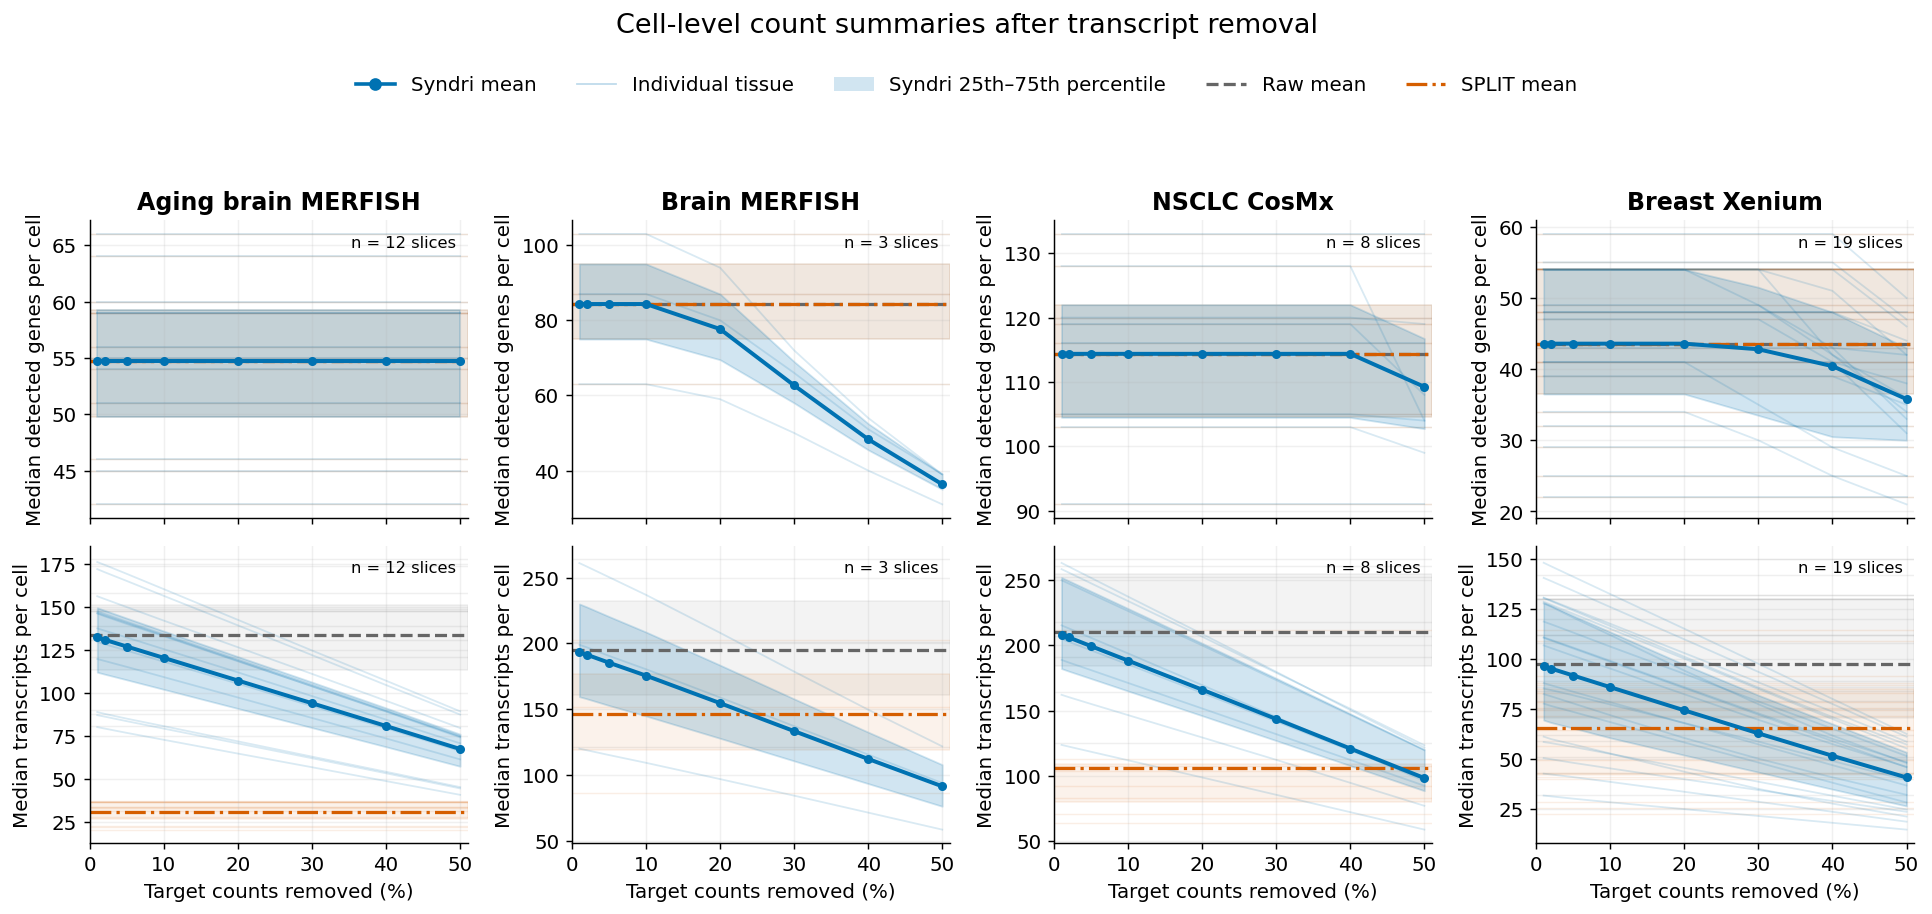

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Assumes `metrics` contains all non_tcell_metrics.csv files and has:
# dataset, slice, case, target_removed_fraction,
# median_genes_per_cell, median_transcripts_per_cell

dataset_titles = {
    "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}

syndri_color = "#0072B2"
raw_color = "#666666"
split_color = "#D55E00"

metric_specs = [
    ("median_genes_per_cell", "Median detected genes per cell"),
    ("median_transcripts_per_cell", "Median transcripts per cell"),
]

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        nrows=len(metric_specs),
        ncols=len(dataset_titles),
        figsize=(15, 7),
        sharex=True,
        squeeze=False,
    )

    for col, (dataset, title) in enumerate(dataset_titles.items()):
        dataset_data = metrics.loc[
            metrics["dataset"].eq(dataset)
        ].copy()

        for row, (metric, ylabel) in enumerate(metric_specs):
            ax = axes[row, col]

            # Raw and SPLIT values, one value per tissue/slice.
            raw = dataset_data.loc[
                dataset_data["case"].eq("admixed"),
                ["slice", metric],
            ].dropna()

            split = dataset_data.loc[
                dataset_data["case"].eq("SPLIT"),
                ["slice", metric],
            ].dropna()

            # Syndri removal-fraction results.
            syndri = dataset_data.loc[
                dataset_data["case"].str.startswith(
                    "cleaned_admixed_removed_frac_",
                    na=False,
                )
                & dataset_data["target_removed_fraction"].notna(),
                ["slice", "target_removed_fraction", metric],
            ].dropna()

            # Individual tissue trajectories.
            for _, tissue in syndri.groupby("slice", observed=True):
                tissue = tissue.sort_values("target_removed_fraction")

                ax.plot(
                    tissue["target_removed_fraction"] * 100,
                    tissue[metric],
                    color=syndri_color,
                    linewidth=1,
                    alpha=0.15,
                    zorder=2,
                )

            # Syndri mean and interquartile range across tissues.
            summary = (
                syndri.groupby("target_removed_fraction", observed=True)[metric]
                .agg(
                    mean="mean",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                )
                .reset_index()
                .sort_values("target_removed_fraction")
            )

            if not summary.empty:
                x = summary["target_removed_fraction"].to_numpy() * 100

                ax.fill_between(
                    x,
                    summary["q25"].to_numpy(),
                    summary["q75"].to_numpy(),
                    color=syndri_color,
                    alpha=0.18,
                    zorder=1,
                )

                ax.plot(
                    x,
                    summary["mean"].to_numpy(),
                    "o-",
                    color=syndri_color,
                    linewidth=2.2,
                    markersize=4,
                    zorder=3,
                )

            # Raw tissue values and aggregate reference.
            if not raw.empty:
                for value in raw[metric]:
                    ax.axhline(
                        value,
                        color=raw_color,
                        linewidth=0.8,
                        alpha=0.10,
                        zorder=0,
                    )

                ax.axhspan(
                    raw[metric].quantile(0.25),
                    raw[metric].quantile(0.75),
                    color=raw_color,
                    alpha=0.08,
                    zorder=0,
                )

                ax.axhline(
                    raw[metric].mean(),
                    color=raw_color,
                    linestyle="--",
                    linewidth=1.8,
                    zorder=2,
                )

            # SPLIT tissue values and aggregate reference.
            if not split.empty:
                for value in split[metric]:
                    ax.axhline(
                        value,
                        color=split_color,
                        linewidth=0.8,
                        alpha=0.10,
                        zorder=0,
                    )

                ax.axhspan(
                    split[metric].quantile(0.25),
                    split[metric].quantile(0.75),
                    color=split_color,
                    alpha=0.08,
                    zorder=0,
                )

                ax.axhline(
                    split[metric].mean(),
                    color=split_color,
                    linestyle="-.",
                    linewidth=1.8,
                    zorder=2,
                )

            n_slices = dataset_data["slice"].nunique()
            ax.text(
                0.97,
                0.95,
                f"n = {n_slices} slices",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9,
            )

            if row == 0:
                ax.set_title(title)

            ax.set_ylabel(ylabel)
            ax.set_xlim(0, 51)
            ax.set_xticks([0, 10, 20, 30, 40, 50])
            ax.grid(alpha=0.18)

            if row == len(metric_specs) - 1:
                ax.set_xlabel("Target counts removed (%)")

    legend = [
        Line2D(
            [0], [0],
            color=syndri_color,
            marker="o",
            linewidth=2,
            label="Syndri mean",
        ),
        Line2D(
            [0], [0],
            color=syndri_color,
            linewidth=1,
            alpha=0.25,
            label="Individual tissue",
        ),
        Patch(
            facecolor=syndri_color,
            alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=raw_color,
            linestyle="--",
            linewidth=1.8,
            label="Raw mean",
        ),
        Line2D(
            [0], [0],
            color=split_color,
            linestyle="-.",
            linewidth=1.8,
            label="SPLIT mean",
        ),
    ]

    fig.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.95),
        ncol=5,
        frameon=False,
    )

    fig.suptitle(
        "Cell-level count summaries after transcript removal",
        y=1.0,
        fontsize=15,
    )

    fig.tight_layout(rect=[0, 0, 1, 0.88])

    # fig.savefig(
    #     "cell_count_summaries.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )
    # fig.savefig(
    #     "cell_count_summaries.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()

/tmp/ipykernel_3861862/475366022.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3861862/475366022.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


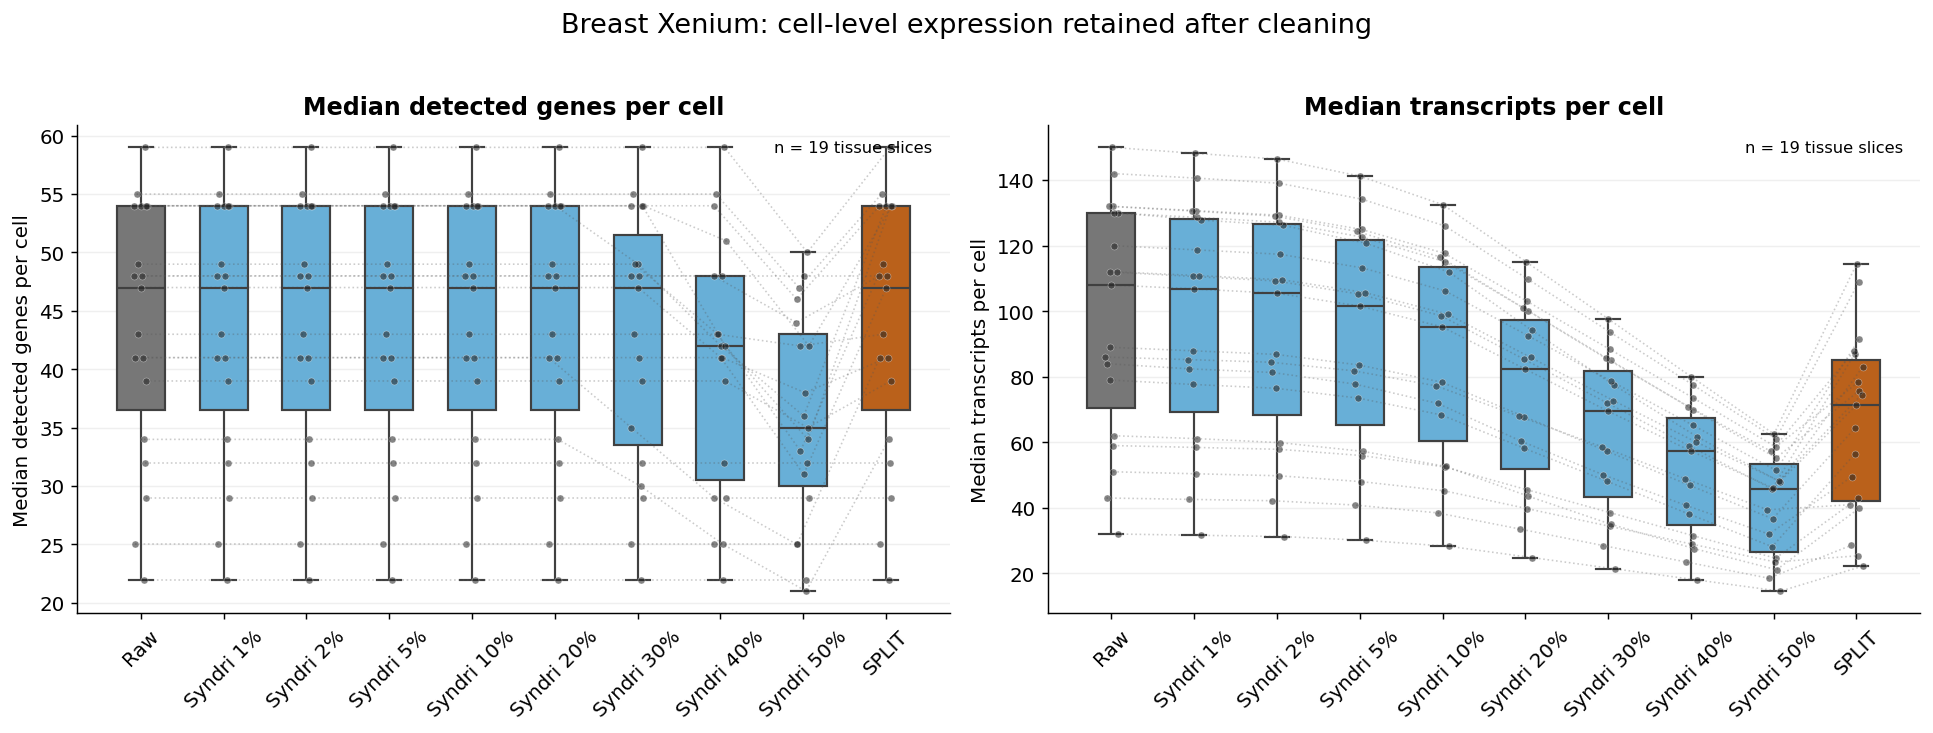

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dataset = "breast_xenium"

metric_specs = [
    ("median_genes_per_cell", "Median detected genes per cell"),
    ("median_transcripts_per_cell", "Median transcripts per cell"),
]

fraction_order = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]

case_order = (
    ["Raw"]
    + [f"Syndri {int(f * 100)}%" for f in fraction_order]
    + ["SPLIT"]
)

plot_data = metrics.loc[
    metrics["dataset"].eq(dataset)
].copy()


def condition_label(row):
    if row["case"] == "admixed":
        return "Raw"

    if row["case"] == "SPLIT":
        return "SPLIT"

    if (
        isinstance(row["case"], str)
        and row["case"].startswith("cleaned_admixed_removed_frac_")
        and pd.notna(row["target_removed_fraction"])
    ):
        return f"Syndri {int(round(row['target_removed_fraction'] * 100))}%"

    return np.nan


plot_data["plot_condition"] = plot_data.apply(
    condition_label,
    axis=1,
)

plot_data = plot_data.loc[
    plot_data["plot_condition"].isin(case_order)
].copy()

plot_data["plot_condition"] = pd.Categorical(
    plot_data["plot_condition"],
    categories=case_order,
    ordered=True,
)

colors = (
    ["#777777"]
    + ["#56B4E9"] * len(fraction_order)
    + ["#D55E00"]
)

rng = np.random.default_rng(0)

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        1,
        len(metric_specs),
        figsize=(15, 5.5),
        squeeze=False,
    )

    for ax, (metric, ylabel) in zip(axes.flat, metric_specs):
        subset = plot_data.loc[
            plot_data[metric].notna(),
            ["slice", "plot_condition", metric],
        ].copy()

        # Boxplots across tissue slices.
        sns.boxplot(
            data=subset,
            x="plot_condition",
            y=metric,
            order=case_order,
            palette=dict(zip(case_order, colors)),
            width=0.58,
            showfliers=False,
            linewidth=1.2,
            ax=ax,
        )

        # Stable horizontal jitter for each tissue.
        slices = sorted(subset["slice"].unique())
        slice_jitter = {
            tissue: rng.uniform(-0.08, 0.08)
            for tissue in slices
        }

        # Dotted paired trajectories for individual tissues.
        for tissue, tissue_data in subset.groupby(
            "slice",
            observed=True,
        ):
            tissue_data = tissue_data.copy()
            tissue_data["x"] = (
                tissue_data["plot_condition"]
                .map({case: i for i, case in enumerate(case_order)})
                .astype(float)
                + slice_jitter[tissue]
            )
            tissue_data = tissue_data.sort_values("x")

            ax.plot(
                tissue_data["x"],
                tissue_data[metric],
                color="#555555",
                linestyle=":",
                linewidth=0.9,
                alpha=0.30,
                zorder=2,
            )

            ax.scatter(
                tissue_data["x"],
                tissue_data[metric],
                color="#222222",
                s=15,
                alpha=0.55,
                edgecolor="white",
                linewidth=0.3,
                zorder=3,
            )

        ax.set_xlabel("")
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel, fontweight="bold")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.20)

        n_slices = subset["slice"].nunique()
        ax.text(
            0.98,
            0.97,
            f"n = {n_slices} tissue slices",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
        )

    fig.suptitle(
        "Breast Xenium: cell-level expression retained after cleaning",
        fontsize=15,
        y=1.02,
    )

    fig.tight_layout()

    # fig.savefig(
    #     "breast_xenium_count_summary_boxplots.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )
    # fig.savefig(
    #     "breast_xenium_count_summary_boxplots.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


base = Path(
    "/work/magroup/skrieger/Syndri/data/datasets"
)

dataset_titles = {
    "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}


# ---------------------------------------------------------
# Load all per-slice admixture-score outputs
# ---------------------------------------------------------

frames = []

for dataset in dataset_titles:
    paths = sorted(
        (
            base
            / dataset
            / "results"
            / "metrics"
            / "admixture_scores"
        ).glob("*/admixture_scores.csv")
    )

    print(f"{dataset}: {len(paths)} slices")

    for path in paths:
        frame = pd.read_csv(path)
        frame["dataset"] = dataset

        if "slice" not in frame.columns:
            frame["slice"] = path.parent.name

        frames.append(frame)

if not frames:
    raise FileNotFoundError(
        "No admixture_scores.csv files were found."
    )

admixture_scores = pd.concat(
    frames,
    ignore_index=True,
)

print(
    f"Loaded {len(admixture_scores):,} score rows from "
    f"{admixture_scores['slice'].nunique()} slices"
)

admixture_scores.setting.unique()

agingbrain_merfish: 12 slices
brain_merfish: 3 slices
nsclc_cosmx: 8 slices
breast_xenium: 19 slices
Loaded 27,611,510 score rows from 42 slices


array(['raw', 'SPLIT', 'syndri_remove_0.01', 'syndri_remove_0.02',
       'syndri_remove_0.05', 'syndri_remove_0.1', 'syndri_remove_0.2',
       'syndri_remove_0.3', 'syndri_remove_0.4', 'syndri_remove_0.5'],
      dtype=object)

In [2]:
# Raw score for every cell.
raw_scores = (
    admixture_scores.loc[
        admixture_scores["setting"].eq("raw"),
        [
            "dataset",
            "slice",
            "source_file",
            "cell",
            "cell_type",
            "scores",
        ],
    ]
    .rename(columns={"scores": "raw_score"})
)

# Syndri-cleaned observations.
syndri_scores = admixture_scores.loc[
    admixture_scores["setting"].str.startswith(
        "syndri_remove_",
        na=False,
    )
    & admixture_scores["removed_frac_target"].notna()
].copy()

# Match every cleaned score with the raw score for the same cell.
paired_scores = syndri_scores.merge(
    raw_scores,
    on=[
        "dataset",
        "slice",
        "source_file",
        "cell",
        "cell_type",
    ],
    how="inner",
    validate="many_to_one",
)

paired_scores["improvement_from_raw"] = (
    paired_scores["raw_score"]
    - paired_scores["scores"]
)

paired_scores["target_removed_pct"] = (
    paired_scores["removed_frac_target"] * 100
)

paired_scores.head()

,source_file,slice,cell,cell_type,scores,dataset,setting,removed_frac_target,removed_frac,removed_pct,threshold,raw_score,improvement_from_raw,target_removed_pct
0,/work/magroup/skrieger/Syndri/data/datasets/ag...,st_integrated_MsBrainAgingSpatialDonor_5_0,76545095880062404449739124739951016660,T cell,0.204111,agingbrain_merfish,syndri_remove_0.01,0.01,0.011983,1.198257,1.0,0.204111,0.0,1.0
1,/work/magroup/skrieger/Syndri/data/datasets/ag...,st_integrated_MsBrainAgingSpatialDonor_5_0,263455324924207972401801960255219265342,T cell,0.230922,agingbrain_merfish,syndri_remove_0.01,0.01,0.011983,1.198257,1.0,0.230922,0.0,1.0
2,/work/magroup/skrieger/Syndri/data/datasets/ag...,st_integrated_MsBrainAgingSpatialDonor_5_0,56017499090938603048736249549259705153,T cell,0.235741,agingbrain_merfish,syndri_remove_0.01,0.01,0.011983,1.198257,1.0,0.235741,0.0,1.0
3,/work/magroup/skrieger/Syndri/data/datasets/ag...,st_integrated_MsBrainAgingSpatialDonor_5_0,178661957727480312799988036961476617746,T cell,0.377010,agingbrain_merfish,syndri_remove_0.01,0.01,0.011983,1.198257,1.0,0.377010,0.0,1.0
4,/work/magroup/skrieger/Syndri/data/datasets/ag...,st_integrated_MsBrainAgingSpatialDonor_5_0,335500661641638132388020480176278029138,T cell,0.329321,agingbrain_merfish,syndri_remove_0.01,0.01,0.011983,1.198257,1.0,0.329321,0.0,1.0


In [3]:
slice_scores = (
    paired_scores.groupby(
        [
            "dataset",
            "slice",
            "target_removed_pct",
        ],
        observed=True,
    )
    .agg(
        median_improvement=(
            "improvement_from_raw",
            "median",
        ),
        mean_improvement=(
            "improvement_from_raw",
            "mean",
        ),
        median_raw_score=("raw_score", "median"),
        median_cleaned_score=("scores", "median"),
        n_cells=("cell", "nunique"),
        achieved_removed_pct=("removed_pct", "median"),
    )
    .reset_index()
)

# Explicit raw baseline at 0% removal for every slice.
baseline_rows = (
    raw_scores.groupby(
        ["dataset", "slice"],
        observed=True,
    )
    .agg(
        median_raw_score=("raw_score", "median"),
        n_cells=("cell", "nunique"),
    )
    .reset_index()
)

baseline_rows["target_removed_pct"] = 0.0
baseline_rows["median_improvement"] = 0.0
baseline_rows["mean_improvement"] = 0.0
baseline_rows["median_cleaned_score"] = (
    baseline_rows["median_raw_score"]
)
baseline_rows["achieved_removed_pct"] = 0.0

slice_scores_with_raw = pd.concat(
    [
        baseline_rows[slice_scores.columns],
        slice_scores,
    ],
    ignore_index=True,
)

slice_scores_with_raw.head()

,dataset,slice,target_removed_pct,median_improvement,mean_improvement,median_raw_score,median_cleaned_score,n_cells,achieved_removed_pct
0,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,0.0,0.0,0.0,0.271462,0.271462,10744,0.0
1,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_1,0.0,0.0,0.0,0.256994,0.256994,9644,0.0
2,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_2,0.0,0.0,0.0,0.276706,0.276706,8983,0.0
3,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_0,0.0,0.0,0.0,0.237088,0.237088,9462,0.0
4,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_1,0.0,0.0,0.0,0.249225,0.249225,8164,0.0


In [4]:
# Pair each SPLIT score with the raw score for the same cell.
split_scores = (
    admixture_scores.loc[
        admixture_scores["setting"].eq("SPLIT")
    ]
    .merge(
        raw_scores,
        on=[
            "dataset",
            "slice",
            "source_file",
            "cell",
            "cell_type",
        ],
        how="inner",
        validate="many_to_one",
    )
)

# Positive means that SPLIT reduced the admixture score.
split_scores["improvement_from_raw"] = (
    split_scores["raw_score"]
    - split_scores["scores"]
)

# One paired summary per tissue slice.
split_slice_scores = (
    split_scores.groupby(
        ["dataset", "slice"],
        observed=True,
    )
    .agg(
        median_improvement=(
            "improvement_from_raw",
            "median",
        ),
        mean_improvement=(
            "improvement_from_raw",
            "mean",
        ),
        median_raw_score=("raw_score", "median"),
        median_split_score=("scores", "median"),
        n_cells=("cell", "nunique"),
    )
    .reset_index()
)

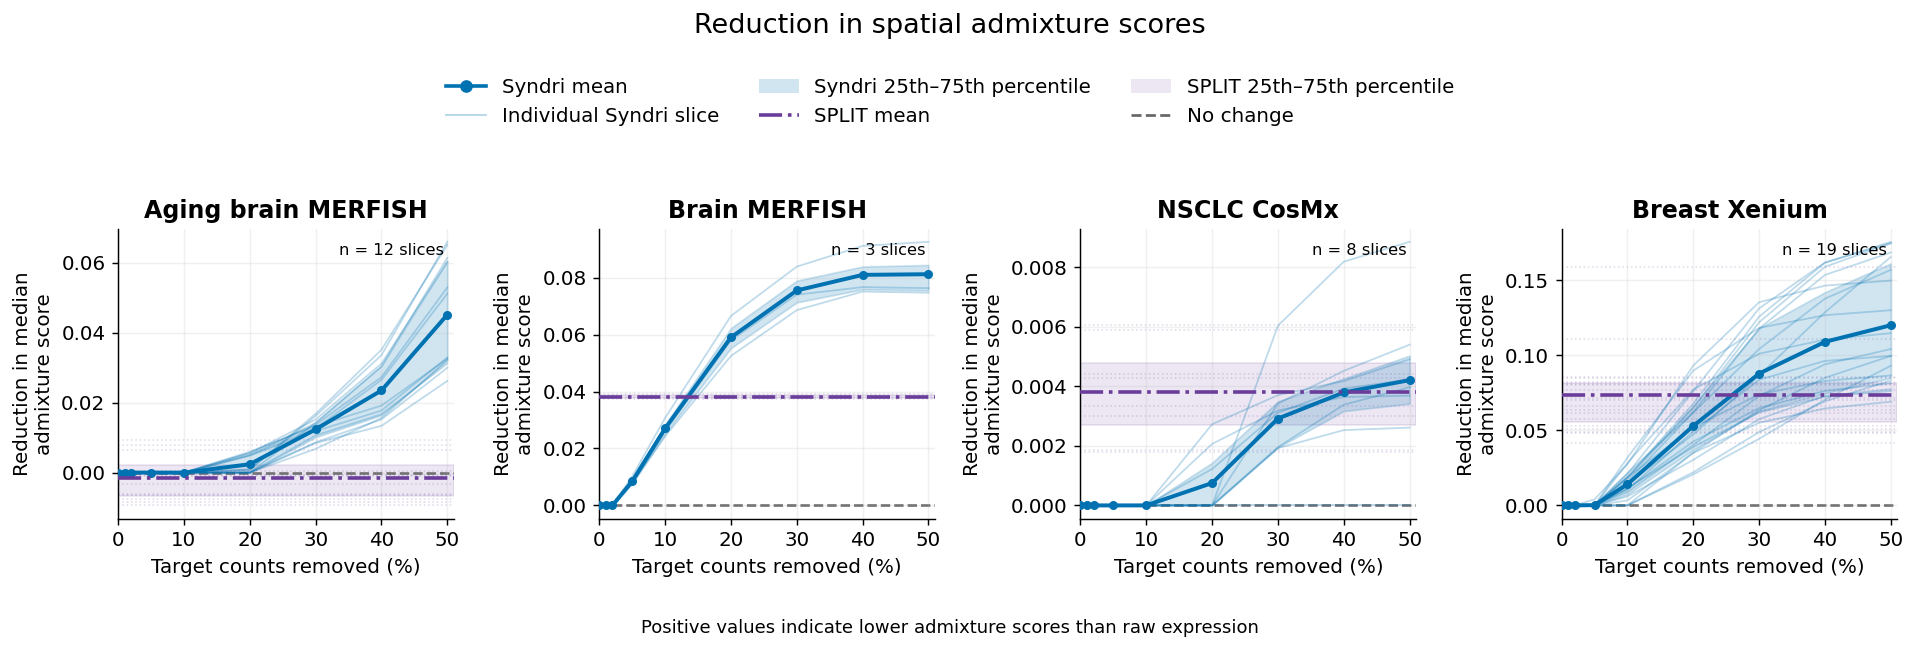

In [6]:
syndri_color = "#0072B2"
split_color = "#6A3D9A"
zero_color = "#666666"

annotate_slice_names = False

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(dataset_titles),
        figsize=(15, 4.5),
        sharex=True,
        squeeze=False,
    )

    for col, (dataset, title) in enumerate(
        dataset_titles.items()
    ):
        ax = axes[0, col]

        subset = slice_scores_with_raw.loc[
            slice_scores_with_raw["dataset"].eq(dataset)
        ].copy()

        split_subset = split_slice_scores.loc[
            split_slice_scores["dataset"].eq(dataset)
        ].copy()

        ax.axhline(
            0,
            color=zero_color,
            linestyle="--",
            linewidth=1.4,
            zorder=1,
        )

        # Individual Syndri tissue-slice trajectories.
        # Individual Syndri tissue-slice trajectories.
        for slice_name, tissue in subset.groupby(
            "slice",
            observed=True,
        ):
            tissue = tissue.sort_values(
                "target_removed_pct"
            )

            ax.plot(
                tissue["target_removed_pct"],
                tissue["median_improvement"],
                color=syndri_color,
                linewidth=1,
                alpha=0.25,
                zorder=2,
            )

            if annotate_slice_names and not tissue.empty:
                endpoint = tissue.iloc[-1]

                ax.annotate(
                    str(slice_name),
                    xy=(
                        endpoint["target_removed_pct"],
                        endpoint["median_improvement"],
                    ),
                    xytext=(4, 0),
                    textcoords="offset points",
                    color=syndri_color,
                    fontsize=6.5,
                    alpha=0.8,
                    ha="left",
                    va="center",
                    clip_on=False,
                )

        # Syndri mean and IQR across slices.
        summary = (
            subset.groupby(
                "target_removed_pct",
                observed=True,
            )["median_improvement"]
            .agg(
                mean="mean",
                median="median",
                q25=lambda x: x.quantile(0.25),
                q75=lambda x: x.quantile(0.75),
                n="size",
            )
            .reset_index()
            .sort_values("target_removed_pct")
        )

        if not summary.empty:
            x = summary["target_removed_pct"].to_numpy()

            ax.fill_between(
                x,
                summary["q25"].to_numpy(),
                summary["q75"].to_numpy(),
                color=syndri_color,
                alpha=0.18,
                zorder=1,
            )

            ax.plot(
                x,
                summary["mean"].to_numpy(),
                "o-",
                color=syndri_color,
                linewidth=2.2,
                markersize=4,
                zorder=3,
            )

        # Individual SPLIT slice values.
        if not split_subset.empty:
            for value in split_subset["median_improvement"]:
                ax.axhline(
                    value,
                    color=split_color,
                    linestyle=":",
                    linewidth=0.9,
                    alpha=0.18,
                    zorder=1,
                )

            # SPLIT interquartile range.
            ax.axhspan(
                split_subset["median_improvement"].quantile(0.25),
                split_subset["median_improvement"].quantile(0.75),
                color=split_color,
                alpha=0.12,
                zorder=0,
            )

            # SPLIT mean across slices.
            ax.axhline(
                split_subset["median_improvement"].mean(),
                color=split_color,
                linestyle="-.",
                linewidth=2,
                zorder=3,
            )

        n_slices = subset["slice"].nunique()

        ax.text(
            0.97,
            0.95,
            f"n = {n_slices} slices",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
        )

        ax.set_title(title)
        ax.set_xlabel("Target counts removed (%)")
        ax.set_ylabel(
            "Reduction in median\nadmixture score"
        )
        ax.set_xlim(0, 51)
        ax.set_xticks(
            [0, 10, 20, 30, 40, 50]
        )
        ax.grid(alpha=0.18)

    legend = [
        Line2D(
            [0],
            [0],
            color=syndri_color,
            marker="o",
            linewidth=2,
            label="Syndri mean",
        ),
        Line2D(
            [0],
            [0],
            color=syndri_color,
            linewidth=1,
            alpha=0.3,
            label="Individual Syndri slice",
        ),
        Patch(
            facecolor=syndri_color,
            alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Line2D(
            [0],
            [0],
            color=split_color,
            linestyle="-.",
            linewidth=2,
            label="SPLIT mean",
        ),
        Patch(
            facecolor=split_color,
            alpha=0.12,
            label="SPLIT 25th–75th percentile",
        ),
        Line2D(
            [0],
            [0],
            color=zero_color,
            linestyle="--",
            label="No change",
        ),
    ]

    fig.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        ncol=3,
        frameon=False,
    )

    fig.suptitle(
        "Reduction in spatial admixture scores",
        fontsize=15,
        y=1.04,
    )

    fig.text(
        0.5,
        -0.02,
        "Positive values indicate lower admixture scores than raw expression",
        ha="center",
        fontsize=10,
    )

    fig.tight_layout(
        rect=[0, 0.04, 1, 0.84]
    )

    # fig.savefig(
    #     "admixture_score_improvement_with_split.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )
    # fig.savefig(
    #     "admixture_score_improvement_with_split.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# Load CosMx admixture scores
# ---------------------------------------------------------

score_root = Path(
    "/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/metrics/admixture_scores_celladmix"
)

frames = []

for path in sorted(score_root.glob("*/admixture_scores.csv")):
    frame = pd.read_csv(path)

    if "slice" not in frame.columns:
        frame["slice"] = path.parent.name

    frames.append(frame)

if not frames:
    raise FileNotFoundError(
        f"No admixture_scores.csv files found under {score_root}"
    )

scores = pd.concat(
    frames,
    ignore_index=True,
)

print(
    f"Loaded {len(scores):,} rows from "
    f"{scores['slice'].nunique()} slices"
)

Loaded 7,712,360 rows from 8 slices


In [16]:
scores

,source_file,slice,cell,cell_type,scores,dataset,total_counts,n_admixture_genes,score_status,setting,removed_frac_target,removed_frac,removed_pct,threshold,score_version
0,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung12_adata_annotated,1,neutrophil,0.000000,spatial,108,148,ok,raw,0.0,0.0,0.000000,NaN,3_celladmix_R
1,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung12_adata_annotated,2,tumor,0.000000,spatial,70,29,ok,raw,0.0,0.0,0.000000,NaN,3_celladmix_R
2,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung12_adata_annotated,3,tumor,0.000000,spatial,93,29,ok,raw,0.0,0.0,0.000000,NaN,3_celladmix_R
3,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung12_adata_annotated,4,tumor,0.003458,spatial,394,29,ok,raw,0.0,0.0,0.000000,NaN,3_celladmix_R
4,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung12_adata_annotated,5,tumor,0.000000,spatial,52,29,ok,raw,0.0,0.0,0.000000,NaN,3_celladmix_R
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7712355,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung9-Rep2_adata_annotated,800549,tumor,0.017055,spatial,22,16,ok,syndri_remove_0.5,0.5,0.5,50.000032,0.912117,3_celladmix_R
7712356,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung9-Rep2_adata_annotated,800550,tumor,0.000000,spatial,34,16,ok,syndri_remove_0.5,0.5,0.5,50.000032,0.912117,3_celladmix_R
7712357,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung9-Rep2_adata_annotated,800551,tumor,0.000000,spatial,35,16,ok,syndri_remove_0.5,0.5,0.5,50.000032,0.912117,3_celladmix_R
7712358,/work/magroup/skrieger/Syndri/data/datasets/ns...,cosmx_nsclc_Lung9-Rep2_adata_annotated,800552,tumor,0.000000,spatial,27,16,ok,syndri_remove_0.5,0.5,0.5,50.000032,0.912117,3_celladmix_R


In [17]:
fractions_to_plot = [
    # 0.01,
    # 0.02,
    # 0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
]

include_raw = True
include_split = True



def format_setting(row):
    if row["setting"] == "raw":
        return "Raw"

    if row["setting"] == "SPLIT":
        return "SPLIT"

    if (
        str(row["setting"]).startswith("syndri_remove_")
        and pd.notna(row["removed_frac_target"])
    ):
        percentage = int(
            round(row["removed_frac_target"] * 100)
        )
        return f"Syndri {percentage}%"

    return np.nan


plot_scores = scores.copy()
plot_scores["display_setting"] = plot_scores.apply(
    format_setting,
    axis=1,
)

slice_cell_type_scores = (
    plot_scores.groupby(
        [
            "slice",
            "cell_type",
            "display_setting",
        ],
        observed=True,
    )["scores"]
    .median()
    .reset_index()
)

syndri_labels = [
    f"Syndri {int(round(fraction * 100))}%"
    for fraction in fractions_to_plot
]

setting_order = []

if include_raw:
    setting_order.append("Raw")

if include_split:
    setting_order.append("SPLIT")

setting_order.extend(syndri_labels)

plot_scores = plot_scores.loc[
    plot_scores["display_setting"].isin(setting_order)
    & plot_scores["scores"].notna()
    & plot_scores["cell_type"].notna()
].copy()

plot_scores["display_setting"] = pd.Categorical(
    plot_scores["display_setting"],
    categories=setting_order,
    ordered=True,
)

cell_type_order = (
    plot_scores.loc[
        plot_scores["display_setting"].eq("Raw")
    ]
    .groupby("cell_type", observed=True)["scores"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

cell_type_order



['Treg',
 'DC',
 'B-cell',
 'NK',
 'T CD4+',
 'T CD8+',
 'endothelial',
 'epithelial',
 'fibroblast',
 'macrophage',
 'mast',
 'monocyte',
 'neutrophil',
 'plasmablast',
 'tumor']

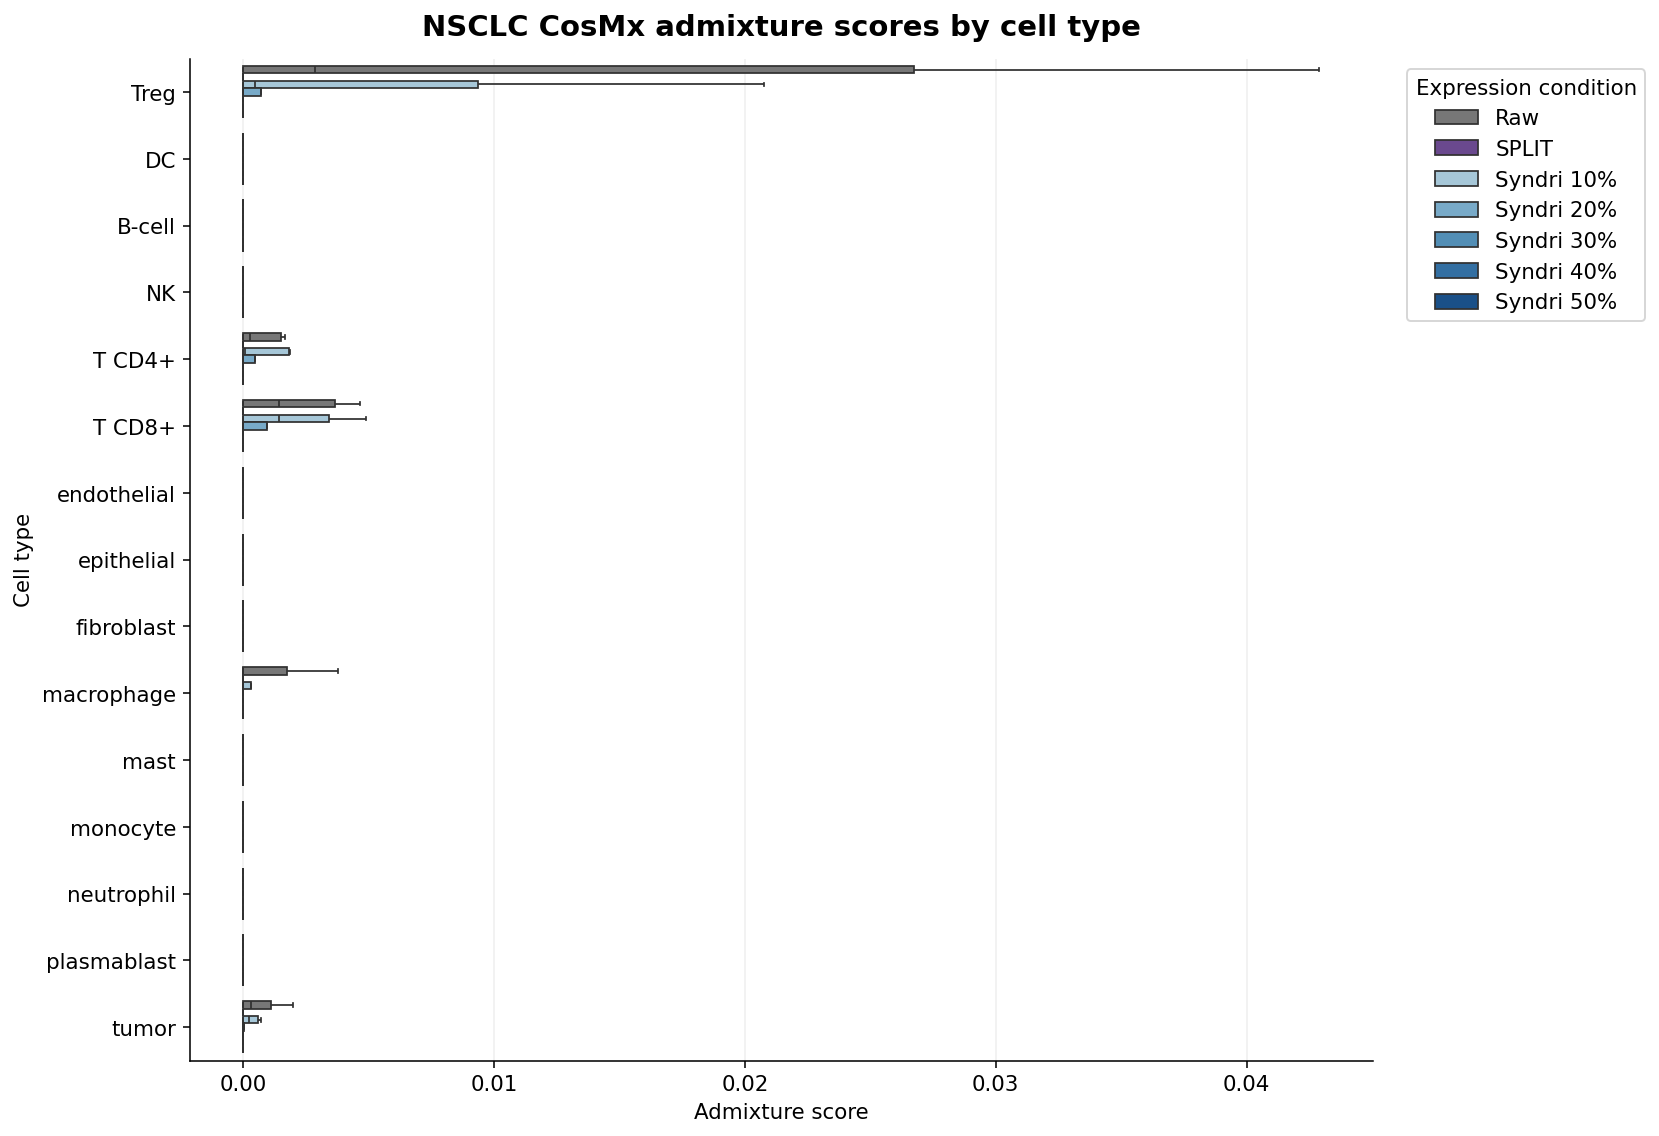

In [18]:
raw_color = "#777777"
split_color = "#6A3D9A"

syndri_colors = sns.color_palette(
    "Blues",
    n_colors=len(syndri_labels) + 2,
)[2:]

palette = {
    "Raw": raw_color,
    "SPLIT": split_color,
    **dict(zip(syndri_labels, syndri_colors)),
}

figure_height = max(
    7,
    0.55 * len(cell_type_order),
)

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 140,
}):
    fig, ax = plt.subplots(
        figsize=(12, figure_height),
    )

    sns.boxplot(
        data=slice_cell_type_scores,
        x="scores",
        y="cell_type",
        hue="display_setting",
        order=cell_type_order,
        hue_order=setting_order,
        palette=palette,
        showfliers=False,
        linewidth=0.9,
        width=0.78,
        ax=ax,
    )

    ax.set_title(
        "NSCLC CosMx admixture scores by cell type",
        fontsize=15,
        pad=12,
    )
    ax.set_xlabel("Admixture score")
    ax.set_ylabel("Cell type")
    ax.grid(
        axis="x",
        alpha=0.20,
    )

    legend = ax.legend(
        title="Expression condition",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=True,
    )

    fig.tight_layout()

    # fig.savefig(
    #     "nsclc_admixture_scores_by_cell_type.png",
    #     dpi=300,
    #     bbox_inches="tight",
    # )
    # fig.savefig(
    #     "nsclc_admixture_scores_by_cell_type.pdf",
    #     bbox_inches="tight",
    # )

    plt.show()

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd

root = Path("/work/magroup/skrieger/Syndri/data/datasets")

datasets = [
    "agingbrain_merfish",
    "brain_merfish",
    "nsclc_cosmx",
    "breast_xenium",
]

frames = []

for dataset in datasets:
    diagnostics_root = (
        root / dataset / "results/metrics/non_tcell"
    )

    for path in diagnostics_root.glob(
        "*/syndri_thresholds/*.csv"
    ):
        frame = pd.read_csv(path)
        frame["dataset"] = dataset
        frame["slice"] = path.parents[1].name
        frame["diagnostic_path"] = str(path)
        frames.append(frame)

if not frames:
    raise FileNotFoundError(
        "No adaptive Syndri threshold diagnostics found."
    )

diagnostics = pd.concat(frames, ignore_index=True)

numeric_columns = [
    "n_removed_genes",
    "removed_count",
    "original_count",
    "n_shared_genes",
    "threshold",
    "cosine_before",
    "cosine_after",
]

for column in numeric_columns:
    if column in diagnostics:
        diagnostics[column] = pd.to_numeric(
            diagnostics[column],
            errors="coerce",
        )

diagnostics["fraction_transcripts_removed"] = np.divide(
    diagnostics["removed_count"],
    diagnostics["original_count"],
    out=np.zeros(len(diagnostics), dtype=float),
    where=diagnostics["original_count"].to_numpy() > 0,
)

diagnostics["fraction_genes_removed"] = np.divide(
    diagnostics["n_removed_genes"],
    diagnostics["n_shared_genes"],
    out=np.zeros(len(diagnostics), dtype=float),
    where=diagnostics["n_shared_genes"].to_numpy() > 0,
)

diagnostics["cosine_improvement"] = (
    diagnostics["cosine_after"]
    - diagnostics["cosine_before"]
)

diagnostics["unchanged"] = (
    diagnostics["n_removed_genes"].fillna(0).eq(0)
)

In [17]:
diagnostics.columns

Index(['source_file', 'input_layer', 'cell_id', 'cell_type', 'threshold',
       'cosine_before', 'cosine_after', 'rolling_cosine', 'n_removed_genes',
       'n_expressed_genes_before', 'removed_count', 'original_count',
       'probability_ordering', 'min_removal_probability', 'status',
       'reference_profiles', 'window', 'n_shared_genes', 'label_key',
       'dataset', 'slice', 'diagnostic_path', 'fraction_transcripts_removed',
       'fraction_genes_removed', 'cosine_improvement', 'unchanged'],
      dtype='object')

In [3]:
def summarize_cell_type(group):
    original = group["original_count"].sum()
    shared_gene_entries = group["n_shared_genes"].sum()

    return pd.Series({
        "n_cells": len(group),
        "n_ok": group["status"].eq("ok").sum(),
        "n_missing_reference": (
            group["status"].eq("missing_reference").sum()
        ),
        "n_unchanged_cells": group["unchanged"].sum(),
        "fraction_unchanged_cells": group["unchanged"].mean(),

        # Cell-gene removal events; a gene removed in two cells counts twice.
        "genes_removed_total": group["n_removed_genes"].sum(),
        "genes_removed_mean_per_cell": (
            group["n_removed_genes"].mean()
        ),
        "genes_removed_median_per_cell": (
            group["n_removed_genes"].median()
        ),
        "genes_removed_q25_per_cell": (
            group["n_removed_genes"].quantile(0.25)
        ),
        "genes_removed_q75_per_cell": (
            group["n_removed_genes"].quantile(0.75)
        ),
        "fraction_cell_gene_entries_removed": (
            group["n_removed_genes"].sum() / shared_gene_entries
            if shared_gene_entries > 0 else np.nan
        ),

        "transcripts_removed_total": (
            group["removed_count"].sum()
        ),
        "transcripts_original_total": original,
        "fraction_transcripts_removed_weighted": (
            group["removed_count"].sum() / original
            if original > 0 else np.nan
        ),
        "transcripts_removed_mean_per_cell": (
            group["removed_count"].mean()
        ),
        "transcripts_removed_median_per_cell": (
            group["removed_count"].median()
        ),
        "fraction_transcripts_removed_median_cell": (
            group["fraction_transcripts_removed"].median()
        ),

        "cosine_improvement_mean": (
            group["cosine_improvement"].mean()
        ),
        "cosine_improvement_median": (
            group["cosine_improvement"].median()
        ),
        "transcripts_removed_variance_per_cell": (
            group["removed_count"].var(ddof=1)
        ),
        "transcripts_removed_sd_per_cell": (
            group["removed_count"].std(ddof=1)
        ),
        "fraction_transcripts_removed_variance_per_cell": (
            group["fraction_transcripts_removed"].var(ddof=1)
        ),
        "fraction_transcripts_removed_sd_per_cell": (
            group["fraction_transcripts_removed"].std(ddof=1)
        ),
    })


cell_type_stats = (
    diagnostics
    .groupby(
        ["dataset", "cell_type"],
        observed=True,
        dropna=False,
    )
    .apply(summarize_cell_type)
    .reset_index()
)

cell_type_stats

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/jwinchel/minic

,dataset,cell_type,n_cells,n_ok,n_missing_reference,n_unchanged_cells,fraction_unchanged_cells,genes_removed_total,genes_removed_mean_per_cell,genes_removed_median_per_cell,...,fraction_transcripts_removed_weighted,transcripts_removed_mean_per_cell,transcripts_removed_median_per_cell,fraction_transcripts_removed_median_cell,cosine_improvement_mean,cosine_improvement_median,transcripts_removed_variance_per_cell,transcripts_removed_sd_per_cell,fraction_transcripts_removed_variance_per_cell,fraction_transcripts_removed_sd_per_cell
0,agingbrain_merfish,T cell,56.0,31.0,25.0,25.0,0.446429,988.0,17.642857,14.0,...,0.460966,45.339286,24.0,0.740533,0.132248,0.131830,2839.537338,53.287309,0.194240,0.440726
1,agingbrain_merfish,astrocyte,13139.0,13139.0,0.0,7.0,0.000533,526228.0,40.050841,38.0,...,0.939796,99.408479,87.0,0.946809,0.120046,0.098102,3432.738065,58.589573,0.003868,0.062196
2,agingbrain_merfish,cell,451.0,261.0,190.0,190.0,0.421286,13325.0,29.545455,28.0,...,0.608436,59.070953,48.0,0.865079,0.196391,0.168376,4020.697177,63.408968,0.215977,0.464733
3,agingbrain_merfish,endothelial cell,10869.0,10869.0,0.0,2.0,0.000184,350713.0,32.267274,30.0,...,0.817593,76.958138,66.0,0.822222,0.076764,0.061664,2265.675925,47.599117,0.020656,0.143721
4,agingbrain_merfish,inhibitory interneuron,9112.0,9112.0,0.0,0.0,0.000000,474890.0,52.116989,52.0,...,0.756929,106.348881,97.0,0.807692,0.137750,0.135279,3350.431117,57.882909,0.021013,0.144958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,nsclc_cosmx,Neutrophil,67726.0,67626.0,0.0,105.0,0.001550,5361186.0,79.159939,68.0,...,0.912506,126.122745,101.0,0.931818,0.274399,0.251442,8734.781907,93.460055,0.007081,0.084147
65,nsclc_cosmx,Plasmablast,38575.0,37976.0,0.0,616.0,0.015969,2755338.0,71.428075,63.0,...,0.694044,158.074660,123.0,0.697368,0.182835,0.148828,17536.444366,132.425241,0.037358,0.193282
66,nsclc_cosmx,T CD4+,46177.0,44824.0,0.0,1354.0,0.029322,4194202.0,90.828811,86.0,...,0.930102,162.033566,141.0,0.946602,0.339201,0.365899,13018.028456,114.096575,0.029573,0.171968
67,nsclc_cosmx,T CD8+,16070.0,15955.0,0.0,116.0,0.007218,1410199.0,87.753516,80.0,...,0.929012,150.022340,123.0,0.952381,0.311333,0.329294,13335.799675,115.480733,0.013286,0.115265


In [1]:
cell_type_stats[cell_type_stats['dataset']=='breast_xenium'].columns

NameError: name 'cell_type_stats' is not defined

In [5]:
cell_type_stats[cell_type_stats['dataset']=='breast_xenium'][['dataset','cell_type','transcripts_removed_total','fraction_transcripts_removed_variance_per_cell']]

,dataset,cell_type,transcripts_removed_total,fraction_transcripts_removed_variance_per_cell
39,breast_xenium,"CD4-positive, alpha-beta memory T cell",1540329.0,0.022312
40,breast_xenium,capillary endothelial cell,6133405.0,0.039709
41,breast_xenium,classical monocyte,7691031.0,0.026483
42,breast_xenium,cytotoxic T cell,3419488.0,0.034285
43,breast_xenium,fibroblast of breast,5589716.0,0.051814
44,breast_xenium,fibroblast of lung,10805588.0,0.059737
45,breast_xenium,macrophage,3522125.0,0.056816
46,breast_xenium,malignant cell,76341214.0,0.060302
47,breast_xenium,mast cell,1215220.0,0.033357
48,breast_xenium,natural T-regulatory cell,1639909.0,0.030989


/tmp/ipykernel_4177226/2221679283.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')


[Text(0, 0, 'classical monocyte'),
 Text(1, 0, 'fibroblast of breast'),
 Text(2, 0, 'smooth muscle cell'),
 Text(3, 0, 'fibroblast of lung'),
 Text(4, 0, 'natural T-regulatory cell'),
 Text(5, 0, 'plasma cell'),
 Text(6, 0, 'natural killer cell'),
 Text(7, 0, 'cytotoxic T cell'),
 Text(8, 0, 'capillary endothelial cell'),
 Text(9, 0, 'CD4-positive, alpha-beta memory T cell'),
 Text(10, 0, 'mast cell'),
 Text(11, 0, 'pericyte'),
 Text(12, 0, 'malignant cell'),
 Text(13, 0, 'macrophage'),
 Text(14, 0, 'plasmacytoid dendritic cell')]

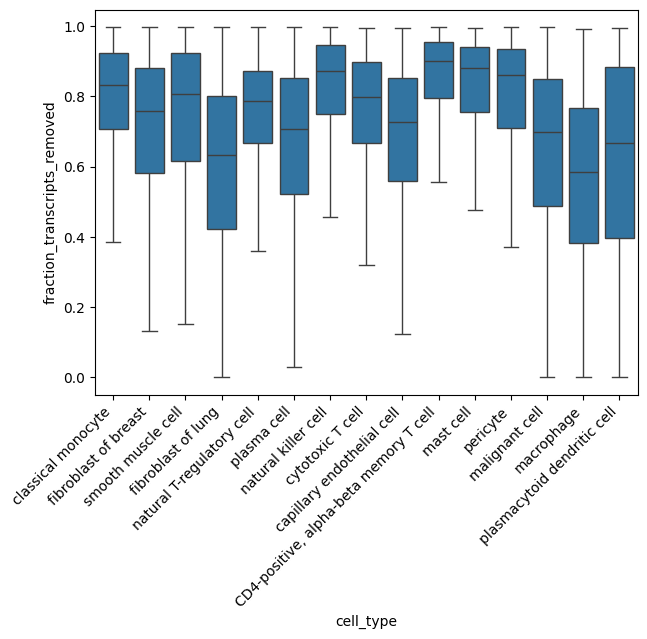

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=diagnostics[diagnostics['dataset']=='breast_xenium'],x='cell_type',y='fraction_transcripts_removed',ax=ax,showfliers=False)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
# fig.show()

In [ ]:
diagnostics['original_count']

0          152.0
1          180.0
2           59.0
3          162.0
4           42.0
           ...  
2786843     13.0
2786844     10.0
2786845     10.0
2786846     11.0
2786847     16.0
Name: original_count, Length: 2786848, dtype: float64

/tmp/ipykernel_4177226/3193628960.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')


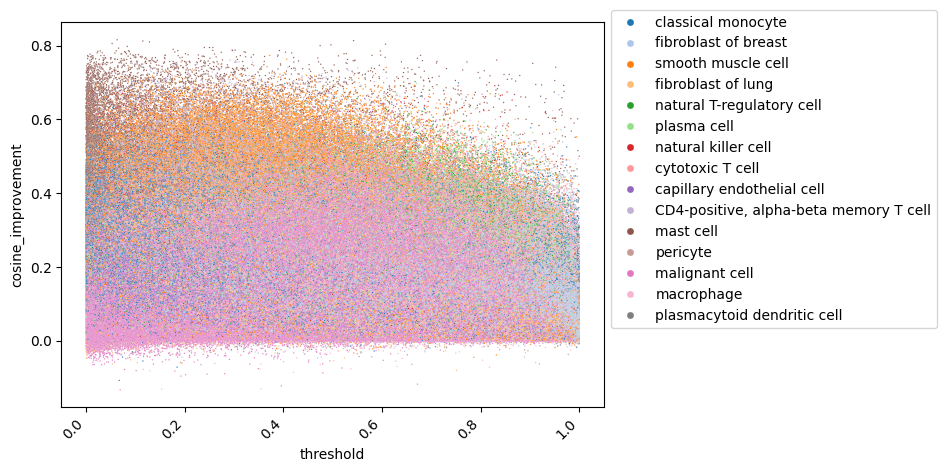

In [10]:
fig,ax = plt.subplots(figsize=(7,5))
sns.scatterplot(data=diagnostics[diagnostics['dataset']=='breast_xenium'],x='threshold',y='cosine_improvement',ax=ax,hue='cell_type',s=1,palette='tab20')
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)